## Setup and Imports

### Installation & Imports


In [166]:
%pip install pandas numpy matplotlib seaborn plotly
%pip install nbformat ipython

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [167]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [251]:
# Data handling and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Model selection and validation
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV

# Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Machine learning models
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

# Model evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Model saving and loading
import joblib

### Data Understanding

#### Data Load & Preview

In [169]:
# Loading Dataset

data = pd.read_csv("data/train-test.csv")

In [170]:
# Preview

data.head(15)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28
5,TR-000006,Phoenix,Corpus Christi,28.75668,-115.87725,28.61374,-95.89569,1396.4,Flatbed,17018.0,2025-01-01,0.95167,1.92983,2676.98
6,TR-000007,Fresno,San Antonio,33.07921,-119.79528,29.50969,-98.40059,1502.6,Dry Van,19112.0,2025-01-01,0.95696,1.82074,2718.54
7,TR-000008,San Francisco,Kansas City,35.19670,-121.69849,39.41104,-91.12450,1976.9,Dry Van,29169.0,2025-01-01,0.97818,1.78430,3522.92
8,TR-000009,Bakersfield,Montgomery,33.28832,-116.67935,31.37602,-86.10743,2027.7,Dry Van,35018.0,2025-01-01,0.96534,1.79522,3675.27
9,TR-000010,Albuquerque,Phoenix,35.39918,-109.59792,28.75668,-115.87725,717.1,Flatbed,34671.0,2025-01-01,0.98475,2.17079,1578.83


#### Data Description 

This dataset contains **freight load** details, and we are going to use it to understand what affects freight rates and predict the posted_rate for new loads.

**load_id** - A unique ID for each load.

**pickup** - Pickup location name.

**delivery** - Delivery location name.

**pickup_lat** - Pickup location latitude.

**pickup_lon** - Pickup location longitude.

**delivery_lat** - Delivery location latitude.

**delivery_lon** - Delivery location longitude.

**distance** - Distance to be covered for the delivery process (assuming it is in km).

**equipment** - The type of truck required to transport the load.

**weight** - The weight of the goods being transported.

**date** - The date associated with the load.

**market_index** - A numerical indicator representing overall freight market conditions (As per research)

**quote_signal** - A numerical indicator that may represent pricing pressure or rate adjustments (As per research)

**posted_rate** - The rate quoted or posted for transportation (The target value)

#### Displaying dataset details

In [171]:
# Features info

print("\nFeature Names:", data.columns.tolist())
print("\nNumber of Features:", len(data.columns))
print("\nNumber of Records:", len(data))


Feature Names: ['load_id', 'pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal', 'posted_rate']

Number of Features: 14

Number of Records: 48000


In [172]:
# To understand the unique values

data.nunique()

load_id         48000
pickup             64
delivery           64
pickup_lat         64
pickup_lon         63
delivery_lat       64
delivery_lon       63
distance        21204
equipment           3
weight          23678
date              304
market_index    32884
quote_signal    37633
posted_rate     45398
dtype: int64

In [173]:
# To view the actual unique equipment types

data["equipment"].unique()

<StringArray>
['Dry Van', 'Reefer', 'Flatbed']
Length: 3, dtype: str

### Basic Data Pre-Processing

#### Cleaning

##### Over View

In [174]:
data.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [175]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  str    
 1   pickup        48000 non-null  str    
 2   delivery      48000 non-null  str    
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  str    
 9   weight        47700 non-null  float64
 10  date          48000 non-null  str    
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), str(5)
memory usage: 5.1 MB


In [176]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
pickup_lat,48000.0,35.647545,4.315285,28.35765,31.98691,35.29479,39.411040,44.30296
pickup_lon,48000.0,-90.928964,13.482431,-121.69849,-98.40059,-88.08915,-83.285060,-69.50000
delivery_lat,48000.0,35.641175,4.317199,28.35765,31.98691,35.29479,39.411040,44.30296
delivery_lon,48000.0,-90.857310,13.476589,-121.69849,-98.40059,-87.52871,-83.285060,-69.50000
distance,48000.0,1135.856654,728.564416,70.00000,550.40000,953.30000,1645.525000,3439.80000
weight,47700.0,31028.844004,9391.440620,-47500.00000,25800.00000,31436.50000,37018.000000,47500.00000
market_index,47626.0,1.083387,0.168091,0.67639,0.94967,1.05580,1.219590,1.46778
quote_signal,48000.0,2.062468,0.291391,0.69228,1.89103,2.05575,2.221685,3.61035
posted_rate,48000.0,2373.980682,1486.493245,57.22000,1251.55500,2030.76000,3330.750000,25533.00000


In [177]:
# To count records with weight less than or equal to 0

invalid_weight = (data["weight"] <= 0).sum()

print("Number of records with weight <= 0:", invalid_weight)

Number of records with weight <= 0: 292


In [178]:
# To inspect records with invalid weight values

data[data["weight"] <= 0]

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
68,TR-000069,Amarillo,Dayton,33.17137,-104.36789,39.87206,-85.62931,1334.2,Reefer,-36559.0,2025-01-01,0.96102,2.11777,2831.27
204,TR-000205,Fresno,Tucson,33.07921,-119.79528,30.92733,-113.23037,496.2,Dry Van,-26670.0,2025-01-02,0.96903,2.13155,1046.92
206,TR-000207,Columbia,Raleigh,34.63570,-83.28506,35.37376,-77.47605,411.3,Reefer,-20003.0,2025-01-02,0.94800,2.31682,959.15
225,TR-000226,Greensboro,Lubbock,35.98195,-82.78379,29.87534,-99.85456,1317.4,Reefer,-23981.0,2025-01-02,1.00820,2.13918,2836.00
376,TR-000377,Madison,Providence,41.70243,-89.85588,37.37287,-69.50000,1331.1,Dry Van,-41397.0,2025-01-03,0.94787,1.91867,2522.54
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47404,TR-047405,Baton Rouge,Memphis,30.50134,-92.65374,35.56802,-89.52871,468.7,Dry Van,-24142.0,2025-10-28,0.94219,1.83201,1077.64
47431,TR-047432,Phoenix,Chattanooga,28.75668,-115.87725,35.29792,-87.18651,1978.6,Flatbed,-35617.0,2025-10-28,0.92870,2.00708,4295.45
47735,TR-047736,Houston,Reno,30.71157,-94.76550,39.54838,-118.64843,1689.1,Reefer,-43951.0,2025-10-30,1.04615,1.85824,3933.12
47850,TR-047851,Shreveport,Cincinnati,32.54628,-92.31888,37.15706,-86.77499,538.3,Dry Van,-28144.0,2025-10-31,0.98093,1.86958,1191.61


Note: 292 records have invalid weight values (≤ 0). We'll cross-check other features before removing them during final cleaning.

##### Null Values check

In [179]:
# To check missing values
data.isnull().sum()

load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64

In [180]:
# To check common missing values in 'weight' & 'market_index'
common_nulls = data[data["weight"].isnull() & data["market_index"].isnull()]

print("Records with both values missing:", len(common_nulls))

Records with both values missing: 1


In [181]:
data.corr(numeric_only=True)["market_index"].drop("market_index").sort_values(ascending=False)

posted_rate     0.034165
pickup_lon      0.001432
weight         -0.001331
pickup_lat     -0.001735
distance       -0.002181
delivery_lat   -0.002587
delivery_lon   -0.008487
quote_signal   -0.067827
Name: market_index, dtype: float64

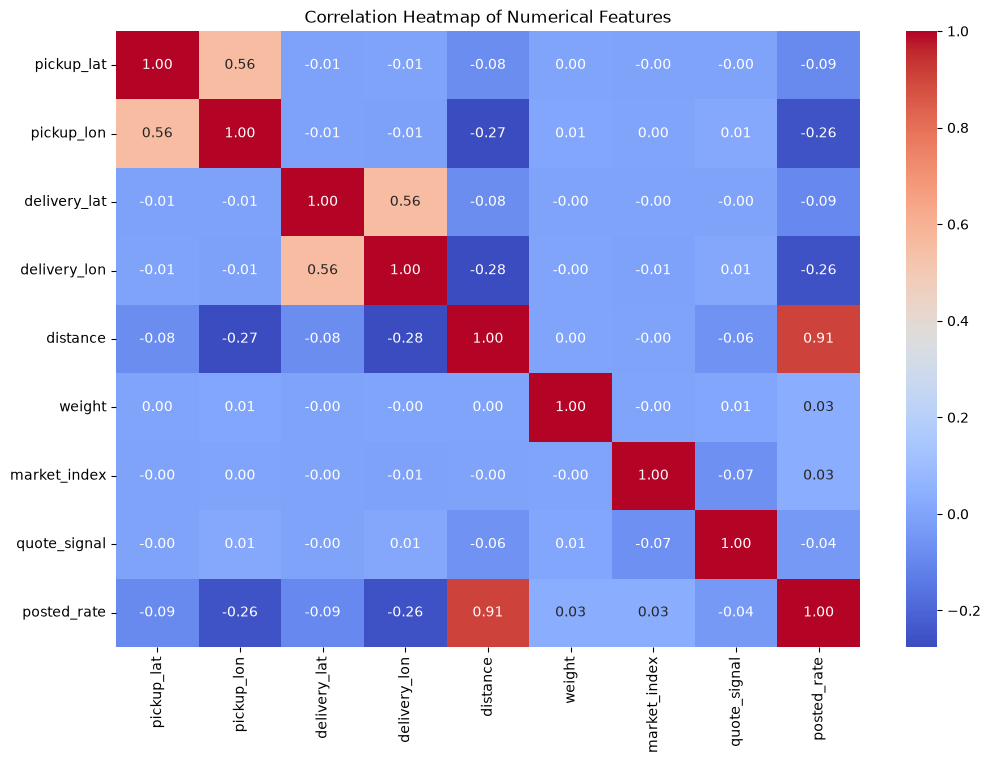

In [182]:
# To calculate the correlation between numerical features
corr_matrix = data.corr(numeric_only=True)

# To plot the correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

**Note:** We can't impute missing weights, and `market_index` has no strong correlation with other numerical features. For now, we'll remove records with `weight` ≤ 0 and the one record where both `weight` and `market_index` are null. We'll decide on the remaining null values during final cleaning.

Basic Removal

In [183]:
# Removing records with weight <= 0, keeping null values
data = data[data["weight"].isna() | (data["weight"] > 0)].copy()

print("Records after cleaning:", len(data))
print("Invalid weight records remaining:", (data["weight"] <= 0).sum())
print("Missing weight values:", data["weight"].isnull().sum())

Records after cleaning: 47708
Invalid weight records remaining: 0
Missing weight values: 300


In [184]:
# Removing records where both weight and market_index are null
data = data.dropna(subset=["weight", "market_index"], how="all").copy()

print("Records after cleaning:", len(data))

Records after cleaning: 47707


#### Duplicate 

In [185]:
# duplicate rows
print("Duplicate records:", data.duplicated().sum())

Duplicate records: 0


### EDA & Data Processing

In [186]:
data.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


##### Outlier Detection

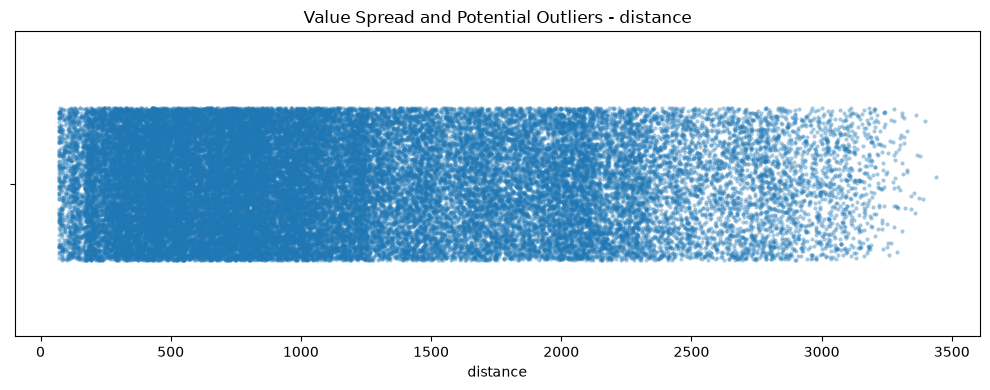

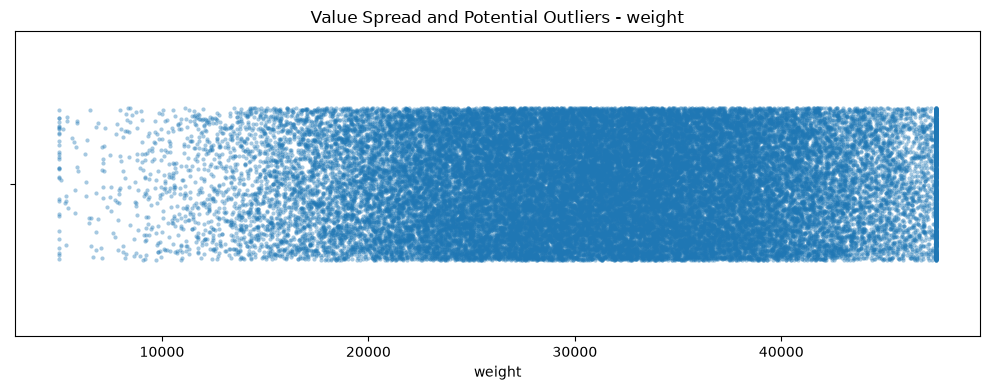

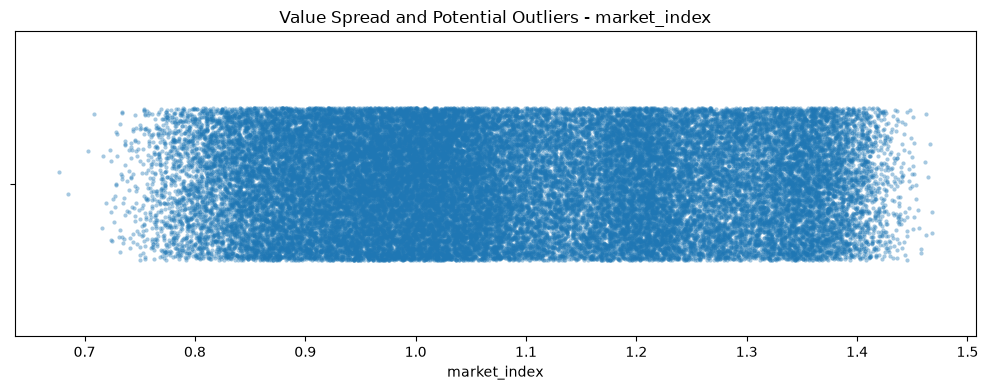

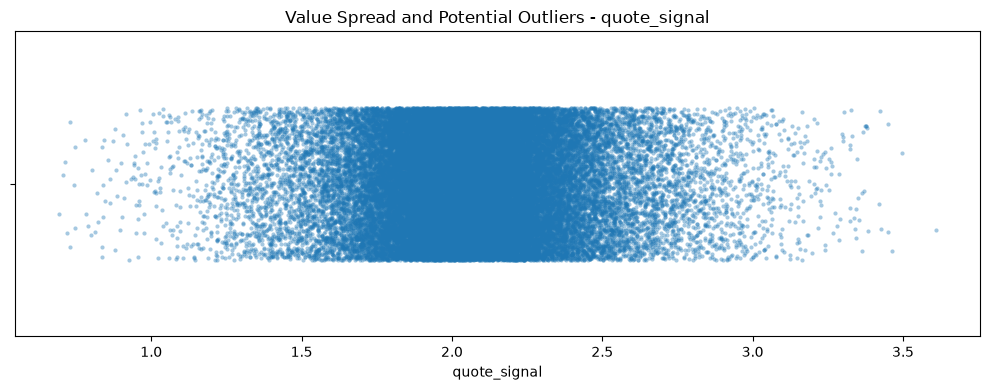

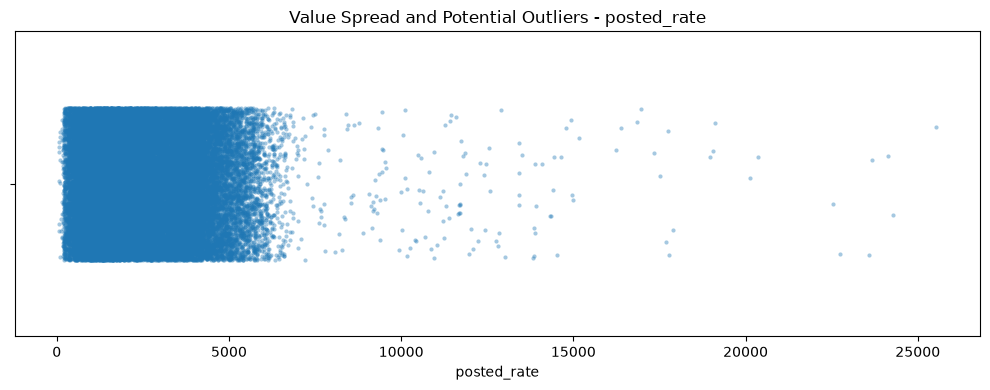

In [187]:
# excluding IDs and geographical coordinates
exclude_features = [
    "load_id",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon"
]

numerical_features = data.select_dtypes(include="number").columns.drop(
    exclude_features, errors="ignore"
)

# Visualize the spread of values and potential outliers
for col in numerical_features:
    plt.figure(figsize=(10, 4))

    sns.stripplot(
        data=data,
        x=col,
        jitter=0.25,
        alpha=0.4,
        size=3
    )

    plt.title(f"Value Spread and Potential Outliers - {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

In [188]:
# Total number of records
total_records = len(data)

# Outlier conditions
outlier_checks = {
    "Distance > 3000": data["distance"] > 3000,
    "Weight < 10000": data["weight"] < 10000,
    "Weight > 40000": data["weight"] > 40000,
    "Market Index below Q1": data["market_index"] < data["market_index"].quantile(0.25),
    "Market Index above Q3": data["market_index"] > data["market_index"].quantile(0.75),
    "Quote Signal below Q1": data["quote_signal"] < data["quote_signal"].quantile(0.25),
    "Quote Signal above Q3": data["quote_signal"] > data["quote_signal"].quantile(0.75),
    "Posted Rate > 5000": data["posted_rate"] > 5000,
    "Posted Rate > 5500": data["posted_rate"] > 5500
}

# Display counts and percentages
for feature, condition in outlier_checks.items():
    count = condition.sum()
    percentage = (count / total_records) * 100

    print(f"{feature}: {count} records ({percentage:.2f}% of {total_records})")

Distance > 3000: 567 records (1.19% of 47707)
Weight < 10000: 202 records (0.42% of 47707)
Weight > 40000: 7071 records (14.82% of 47707)
Market Index below Q1: 11834 records (24.81% of 47707)
Market Index above Q3: 11834 records (24.81% of 47707)
Quote Signal below Q1: 11927 records (25.00% of 47707)
Quote Signal above Q3: 11927 records (25.00% of 47707)
Posted Rate > 5000: 2247 records (4.71% of 47707)
Posted Rate > 5500: 1082 records (2.27% of 47707)


###### Distance

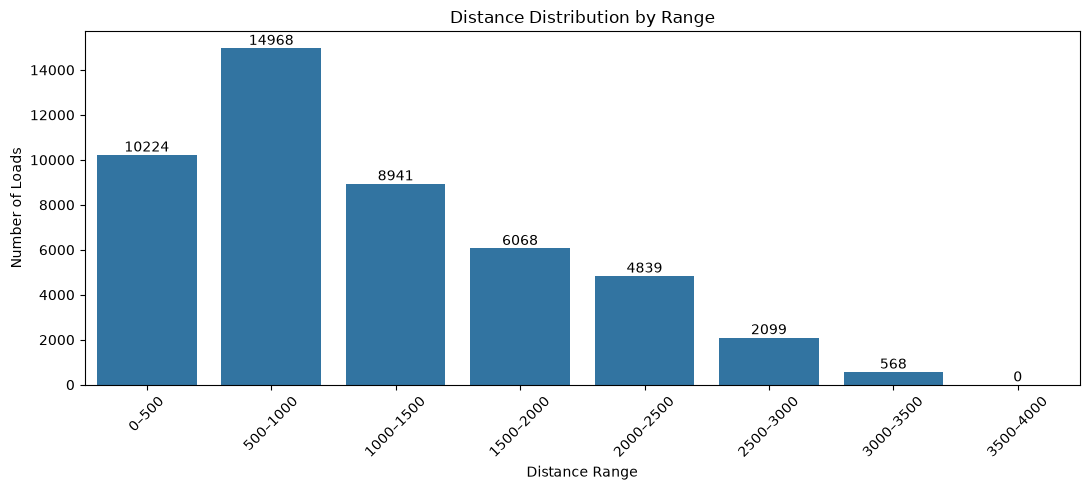

,Load Count,Percentage (%)
distance_range,,
0–500,10224,21.43
500–1000,14968,31.37
1000–1500,8941,18.74
1500–2000,6068,12.72
2000–2500,4839,10.14
2500–3000,2099,4.40
3000–3500,568,1.19
3500–4000,0,0.00


Distance below 0: 0
Distance below 0 or at/above 4000: 0


In [189]:
# Distance

# Distance ranges in steps of 500
bins = list(range(0, 4001, 500))
labels = [f"{bins[i]}–{bins[i+1]}" for i in range(len(bins)-1)]

# Group distances into ranges
distance_data = data.copy()
distance_data["distance_range"] = pd.cut(
    distance_data["distance"],
    bins=bins,
    labels=labels,
    right=False
)

# Count records in each range
distance_counts = distance_data["distance_range"].value_counts(sort=False)

# Plot the distribution
plt.figure(figsize=(11, 5))
ax = sns.barplot(x=distance_counts.index.astype(str),
                 y=distance_counts.values)

plt.title("Distance Distribution by Range")
plt.xlabel("Distance Range")
plt.ylabel("Number of Loads")
plt.xticks(rotation=45)

# Show counts above each bar
for i, count in enumerate(distance_counts.values):
    ax.text(i, count, str(count), ha="center", va="bottom")

plt.tight_layout()
plt.show()

# Display counts and percentages
summary = pd.DataFrame({
    "Load Count": distance_counts,
    "Percentage (%)": (distance_counts / len(data) * 100).round(2)
})

display(summary)

# Check distances outside the displayed ranges
print("Distance below 0:", (data["distance"] < 0).sum())
print("Distance below 0 or at/above 4000:", ((data["distance"] < 0) | (data["distance"] >= 4000)).sum())

The Distance distribution seems reasonable

###### Weight

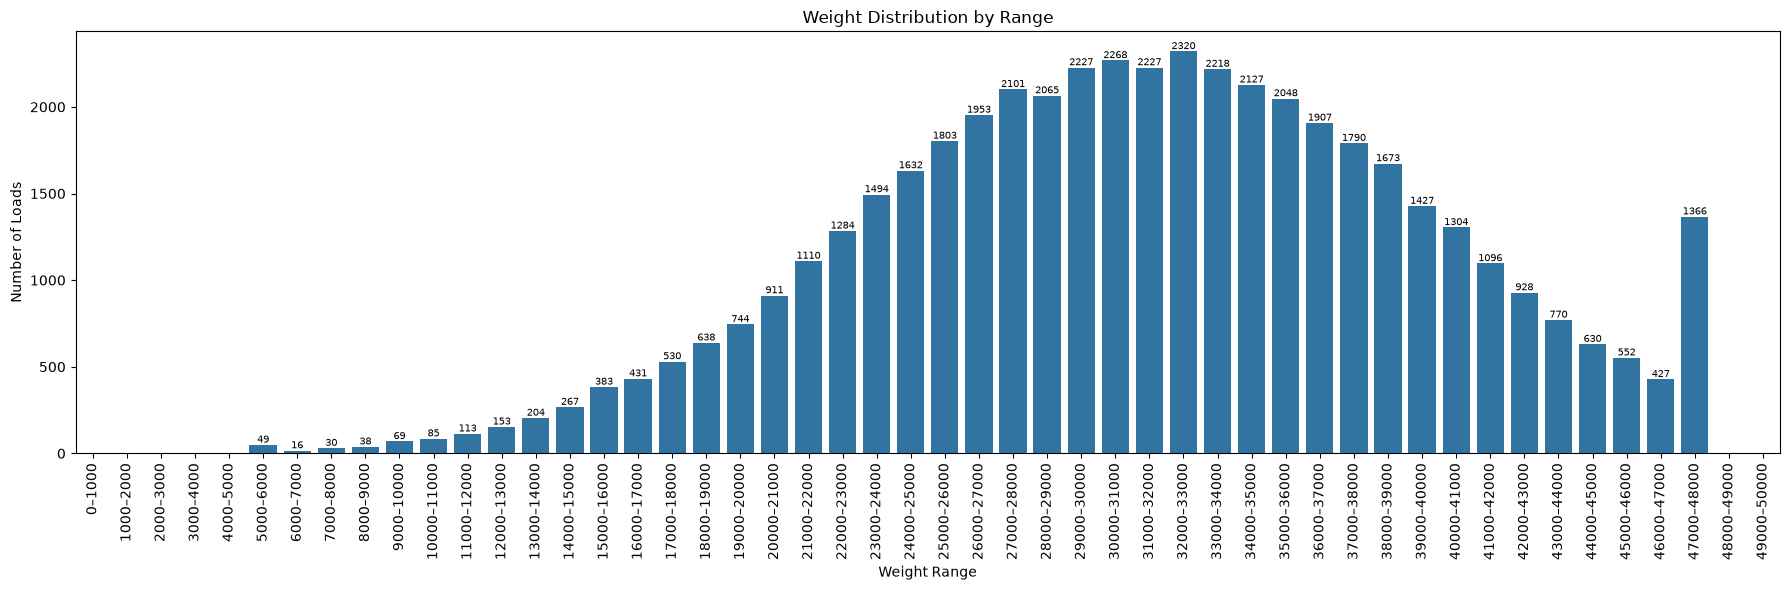

,Load Count,Percentage (%)
weight_range,,
0–1000,0,0.00
1000–2000,0,0.00
2000–3000,0,0.00
3000–4000,0,0.00
4000–5000,0,0.00
5000–6000,49,0.10
6000–7000,16,0.03
7000–8000,30,0.06
8000–9000,38,0.08


Weight below 0: 0
Weight at or above 50000: 0
Missing weight values: 299


In [190]:
# Weight

# Define weight ranges in steps of 1000, starting from 0
bins = list(range(0, 50001, 1000))
labels = [f"{bins[i]}–{bins[i+1]}" for i in range(len(bins)-1)]

# Group weights into ranges
weight_data = data.copy()
weight_data["weight_range"] = pd.cut(
    weight_data["weight"],
    bins=bins,
    labels=labels,
    right=False
)

# Count records in each range
weight_counts = weight_data["weight_range"].value_counts(sort=False)

# Plot the distribution
plt.figure(figsize=(18, 6))
ax = sns.barplot(x=weight_counts.index.astype(str), y=weight_counts.values)

plt.title("Weight Distribution by Range")
plt.xlabel("Weight Range")
plt.ylabel("Number of Loads")
plt.xticks(rotation=90)

# Show counts above bars with records
for i, count in enumerate(weight_counts.values):
    if count > 0:
        ax.text(i, count, str(count), ha="center", va="bottom", fontsize=7)

plt.tight_layout()
plt.show()

# Display counts and percentages
summary = pd.DataFrame({
    "Load Count": weight_counts,
    "Percentage (%)": (weight_counts / len(data) * 100).round(2)
})

display(summary)

# Check values outside the displayed ranges
print("Weight below 0:", (data["weight"] < 0).sum())
print("Weight at or above 50000:", (data["weight"] >= 50000).sum())
print("Missing weight values:", data["weight"].isna().sum())

In [191]:
# Count loads below 10,000 by equipment type
low_weight = data[data["weight"] < 10000]

print("Total loads below 10,000:", len(low_weight))
print("\nCounts by equipment:")
print(low_weight["equipment"].value_counts())

print("\nPercentage below 10,000 by equipment:")
print(
    (pd.crosstab(data["equipment"], data["weight"] < 10000, normalize="index") * 100)
    .round(2)
    .rename(columns={False: "10,000 or above (%)", True: "Below 10,000 (%)"})
)

# Inspect the actual records
display(
    low_weight[
        ["equipment", "weight", "distance", "pickup", "delivery", "posted_rate"]
    ].sort_values("weight").head(30)
)

Total loads below 10,000: 202

Counts by equipment:
equipment
Dry Van    114
Reefer      51
Flatbed     37
Name: count, dtype: int64

Percentage below 10,000 by equipment:
weight     10,000 or above (%)  Below 10,000 (%)
equipment                                       
Dry Van                  99.58              0.42
Flatbed                  99.57              0.43
Reefer                   99.57              0.43


,equipment,weight,distance,pickup,delivery,posted_rate
1610,Dry Van,5000.0,703.5,Greensboro,Shreveport,1352.61
1889,Dry Van,5000.0,1241.1,Indianapolis,Providence,2224.24
1479,Dry Van,5000.0,494.6,Albany,Buffalo,921.49
5431,Dry Van,5000.0,124.2,Columbia,Greensboro,316.01
10076,Reefer,5000.0,706.2,Oklahoma City,Mobile,1651.66
8378,Dry Van,5000.0,206.7,Lexington,Chattanooga,494.03
7247,Dry Van,5000.0,1854.3,Reno,Milwaukee,3124.39
6059,Dry Van,5000.0,524.4,Atlanta,Fort Wayne,1057.70
12778,Dry Van,5000.0,1626.6,Nashville,Salt Lake City,3033.62
28087,Reefer,5000.0,860.8,Dayton,Baton Rouge,2043.61


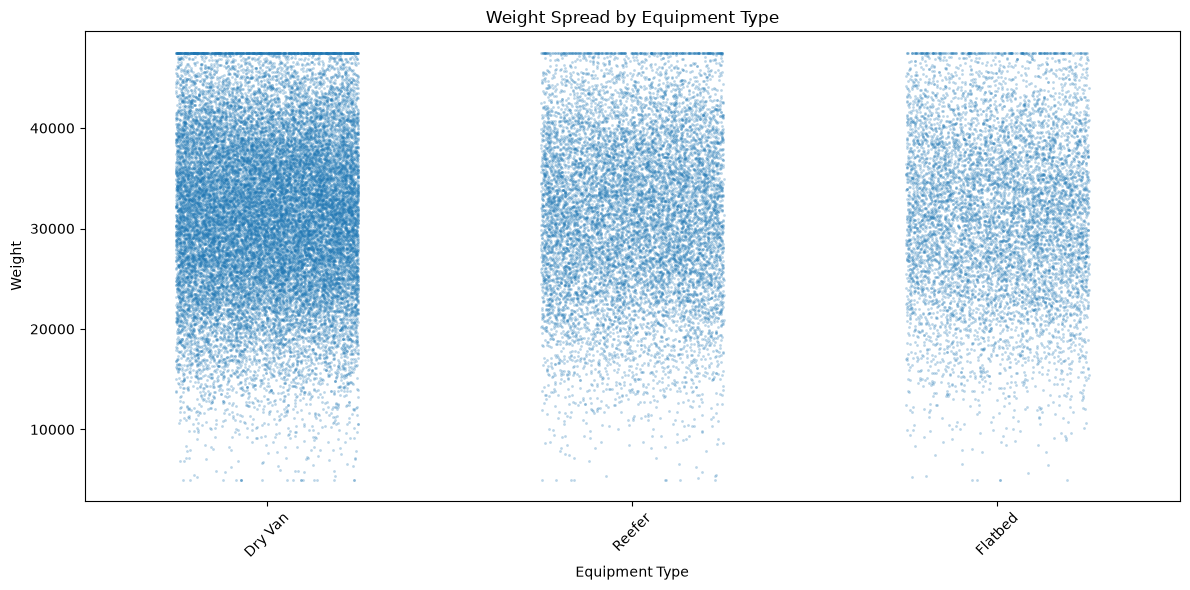

In [192]:
# Spread With Equipment

plt.figure(figsize=(12, 6))

sns.stripplot(
    data=weight_data,
    x="equipment",
    y="weight",
    jitter=0.25,
    alpha=0.3,
    size=2
)

plt.title("Weight Spread by Equipment Type")
plt.xlabel("Equipment Type")
plt.ylabel("Weight")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Conclusion: The weight distribution seems reasonable

###### Market Index

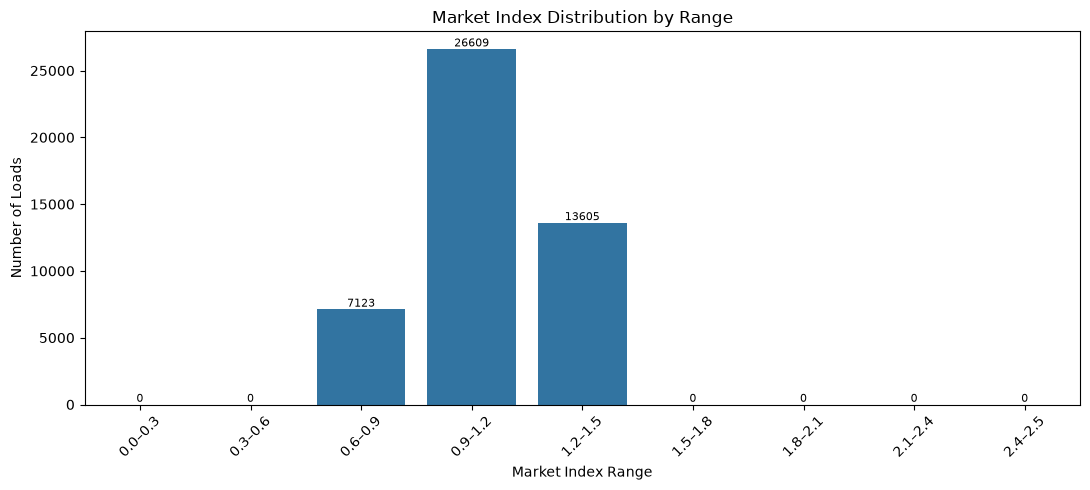

,Load Count,Percentage (%)
market_index_range,,
0.0–0.3,0,0.00
0.3–0.6,0,0.00
0.6–0.9,7123,14.93
0.9–1.2,26609,55.78
1.2–1.5,13605,28.52
1.5–1.8,0,0.00
1.8–2.1,0,0.00
2.1–2.4,0,0.00
2.4–2.5,0,0.00


Market index below 0: 0
Market index at or above 2.5: 0
Missing market index: 370


In [193]:
# Market Index

# Define market index ranges in steps of 0.3
bins = [round(i * 0.3, 1) for i in range(9)]
bins.append(2.5)

labels = [f"{bins[i]}–{bins[i+1]}" for i in range(len(bins)-1)]

# Group market index values into ranges
market_data = data.copy()
market_data["market_index_range"] = pd.cut(
    market_data["market_index"],
    bins=bins,
    labels=labels,
    right=False
)

# Count records in each range
market_counts = market_data["market_index_range"].value_counts(sort=False)

# Plot the distribution
plt.figure(figsize=(11, 5))
ax = sns.barplot(
    x=market_counts.index.astype(str),
    y=market_counts.values
)

plt.title("Market Index Distribution by Range")
plt.xlabel("Market Index Range")
plt.ylabel("Number of Loads")
plt.xticks(rotation=45)

# Display counts above bars
for i, count in enumerate(market_counts.values):
    ax.text(i, count, str(count), ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

# Display counts and percentages
summary = pd.DataFrame({
    "Load Count": market_counts,
    "Percentage (%)": (market_counts / len(data) * 100).round(2)
})

display(summary)

# Check values outside the displayed ranges
print("Market index below 0:", (data["market_index"] < 0).sum())
print("Market index at or above 2.5:", (data["market_index"] >= 2.5).sum())
print("Missing market index:", data["market_index"].isna().sum())

###### Quote

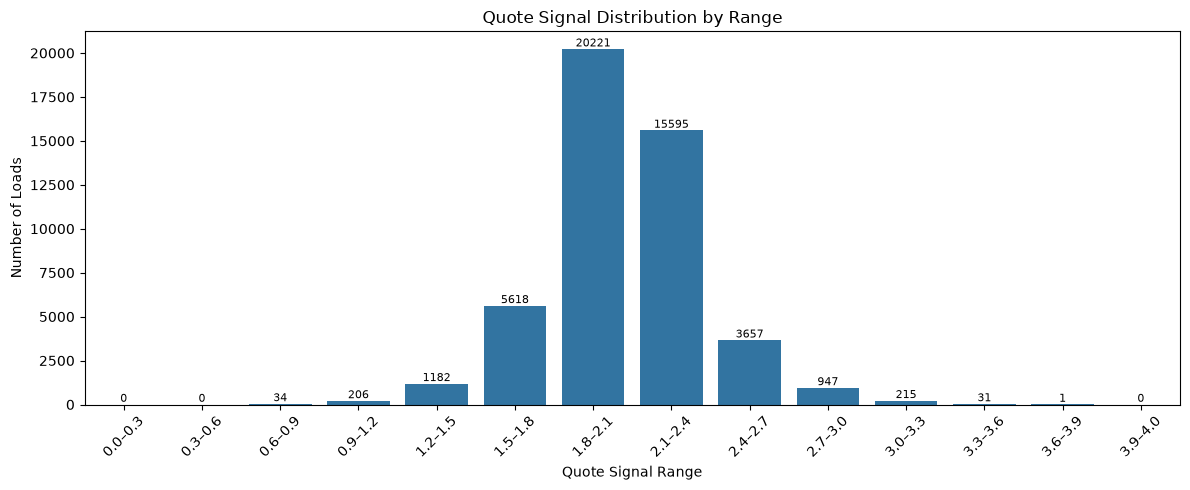

,Load Count,Percentage (%)
quote_signal_range,,
0.0–0.3,0,0.00
0.3–0.6,0,0.00
0.6–0.9,34,0.07
0.9–1.2,206,0.43
1.2–1.5,1182,2.48
1.5–1.8,5618,11.78
1.8–2.1,20221,42.39
2.1–2.4,15595,32.69
2.4–2.7,3657,7.67


Quote signal below 0: 0
Quote signal at or above 4.0: 0
Missing quote signal: 0


In [194]:
# Quote Signal

# Define quote signal ranges in steps of 0.3, up to 4.0
bins = [round(i * 0.3, 1) for i in range(14)]
bins.append(4.0)

labels = [f"{bins[i]}–{bins[i+1]}" for i in range(len(bins)-1)]

# Group quote signal values into ranges
quote_data = data.copy()
quote_data["quote_signal_range"] = pd.cut(
    quote_data["quote_signal"],
    bins=bins,
    labels=labels,
    right=False
)

# Count records in each range
quote_counts = quote_data["quote_signal_range"].value_counts(sort=False)

# Plot the distribution
plt.figure(figsize=(12, 5))
ax = sns.barplot(
    x=quote_counts.index.astype(str),
    y=quote_counts.values
)

plt.title("Quote Signal Distribution by Range")
plt.xlabel("Quote Signal Range")
plt.ylabel("Number of Loads")
plt.xticks(rotation=45)

# Display counts above bars
for i, count in enumerate(quote_counts.values):
    ax.text(i, count, str(count), ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

# Display counts and percentages
summary = pd.DataFrame({
    "Load Count": quote_counts,
    "Percentage (%)": (quote_counts / len(data) * 100).round(2)
})

display(summary)

# Check values outside the displayed ranges
print("Quote signal below 0:", (data["quote_signal"] < 0).sum())
print("Quote signal at or above 4.0:", (data["quote_signal"] >= 4.0).sum())
print("Missing quote signal:", data["quote_signal"].isna().sum())

###### Posted Price

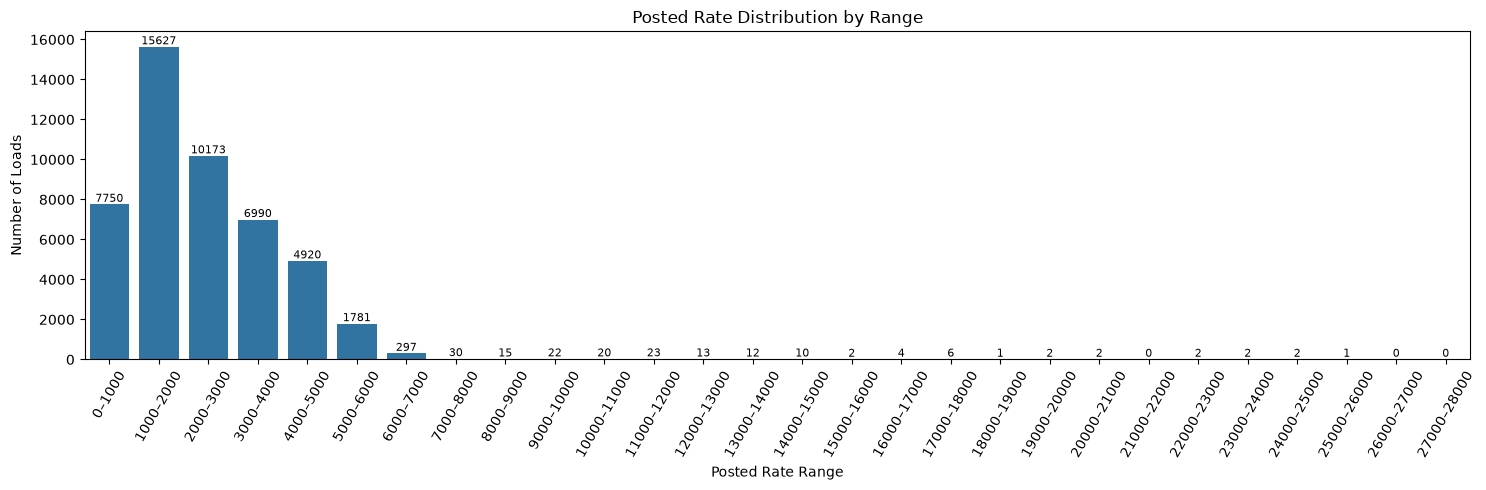

,Load Count,Percentage (%)
posted_rate_range,,
0–1000,7750,16.24
1000–2000,15627,32.76
2000–3000,10173,21.32
3000–4000,6990,14.65
4000–5000,4920,10.31
5000–6000,1781,3.73
6000–7000,297,0.62
7000–8000,30,0.06
8000–9000,15,0.03


Posted rate below 0: 0
Posted rate at or above 28000: 0
Missing posted rate: 0


In [195]:
# Posted Rate

# Define posted rate ranges in steps of 1000
bins = list(range(0, 28001, 1000))
labels = [f"{bins[i]}–{bins[i+1]}" for i in range(len(bins)-1)]

# Group posted rates into ranges
rate_data = data.copy()
rate_data["posted_rate_range"] = pd.cut(
    rate_data["posted_rate"],
    bins=bins,
    labels=labels,
    right=False
)

# Count records in each range
rate_counts = rate_data["posted_rate_range"].value_counts(sort=False)

# Plot the distribution
plt.figure(figsize=(15, 5))
ax = sns.barplot(
    x=rate_counts.index.astype(str),
    y=rate_counts.values
)

plt.title("Posted Rate Distribution by Range")
plt.xlabel("Posted Rate Range")
plt.ylabel("Number of Loads")
plt.xticks(rotation=60)

# Display counts above bars
for i, count in enumerate(rate_counts.values):
    ax.text(i, count, str(count), ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

# Display counts and percentages
summary = pd.DataFrame({
    "Load Count": rate_counts,
    "Percentage (%)": (rate_counts / len(data) * 100).round(2)
})

display(summary)

# Check values outside the displayed ranges
print("Posted rate below 0:", (data["posted_rate"] < 0).sum())
print("Posted rate at or above 28000:", (data["posted_rate"] >= 28000).sum())
print("Missing posted rate:", data["posted_rate"].isna().sum())

In [196]:
# Inspect records with unusually high posted rates
high_rate_data = data[data["posted_rate"] >= 7000].copy()

# Show the details that could explain the high rates
display(
    high_rate_data[
        ["pickup", "delivery", "distance", "equipment",
         "weight", "market_index", "quote_signal", "posted_rate"]
    ].sort_values("posted_rate", ascending=False)
)

print("Records with posted_rate >= 7000:", len(high_rate_data))

# Compare their distance and weight with the full dataset
print("\nHigh-rate records:")
display(high_rate_data[["distance", "weight", "posted_rate"]].describe())

print("\nFull dataset:")
display(data[["distance", "weight", "posted_rate"]].describe())

,pickup,delivery,distance,equipment,weight,market_index,quote_signal,posted_rate
12184,Bakersfield,Hartford,2829.8,Dry Van,33153.0,1.16556,1.83188,25533.00
37764,Phoenix,Syracuse,2810.9,Dry Van,33674.0,1.04877,2.16284,24294.98
1466,Los Angeles,Syracuse,2786.0,Reefer,30322.0,0.98678,1.85370,24140.21
17371,Reno,Philadelphia,2777.6,Reefer,33158.0,1.15070,2.15601,23662.71
26235,Charleston,Phoenix,2552.5,Dry Van,25665.0,1.20224,1.81289,23580.42
...,...,...,...,...,...,...,...,...
26957,Phoenix,Boston,3111.6,Reefer,40391.0,1.39376,2.23711,7011.53
21902,Jacksonville,Baltimore,926.1,Reefer,21481.0,1.16454,1.88682,7010.39
36336,Louisville,San Antonio,953.3,Dry Van,27815.0,0.93015,1.92583,7005.30
45173,Corpus Christi,Atlanta,832.1,Dry Van,47500.0,0.88212,1.87079,7004.30


Records with posted_rate >= 7000: 169

High-rate records:


,distance,weight,posted_rate
count,169.000000,169.000000,169.000000
mean,1646.988166,31627.840237,11647.011420
std,635.428658,7918.536566,3987.299208
min,589.900000,13107.000000,7000.310000
25%,1151.500000,25698.000000,8631.330000
50%,1543.200000,31247.000000,10854.690000
75%,2015.300000,37298.000000,13432.050000
max,3439.800000,47500.000000,25533.000000



Full dataset:


,distance,weight,posted_rate
count,47707.000000,47408.000000,47707.000000
mean,1135.941694,31415.358674,2373.909454
std,728.549463,7994.902979,1485.516545
min,70.000000,5000.000000,57.220000
25%,550.400000,25922.000000,1251.575000
50%,953.300000,31493.500000,2031.180000
75%,1645.900000,37063.000000,3331.320000
max,3439.800000,47500.000000,25533.000000


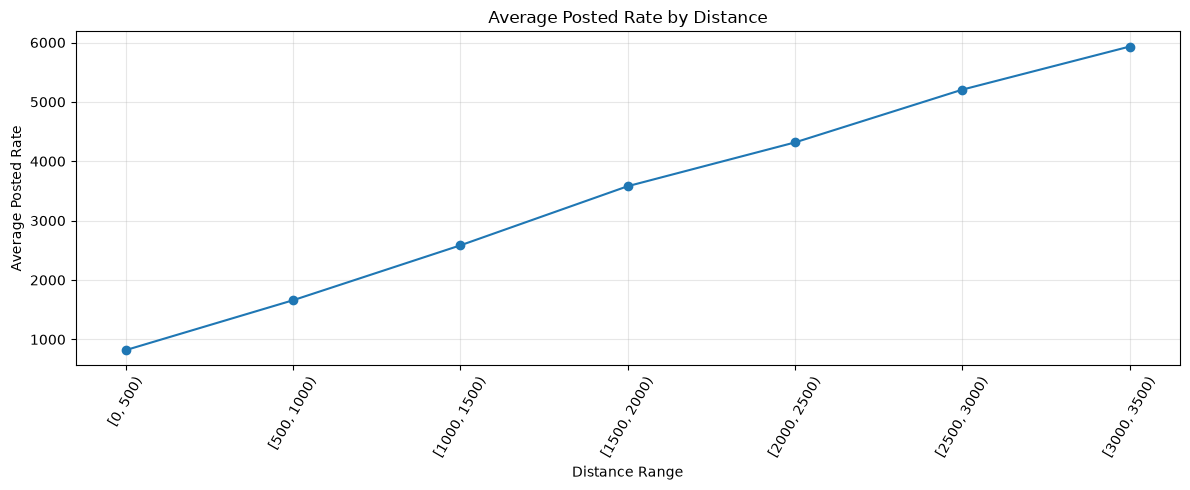

In [197]:
# Compare average posted rate across distance ranges

distance_data = data.copy()

distance_data["distance_range"] = pd.cut(
    distance_data["distance"],
    bins=range(0, int(distance_data["distance"].max()) + 501, 500),
    right=False
)

distance_rate = distance_data.groupby(
    "distance_range", observed=False
)["posted_rate"].mean()

plt.figure(figsize=(12, 5))
plt.plot(
    distance_rate.index.astype(str),
    distance_rate.values,
    marker="o"
)

plt.title("Average Posted Rate by Distance")
plt.xlabel("Distance Range")
plt.ylabel("Average Posted Rate")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

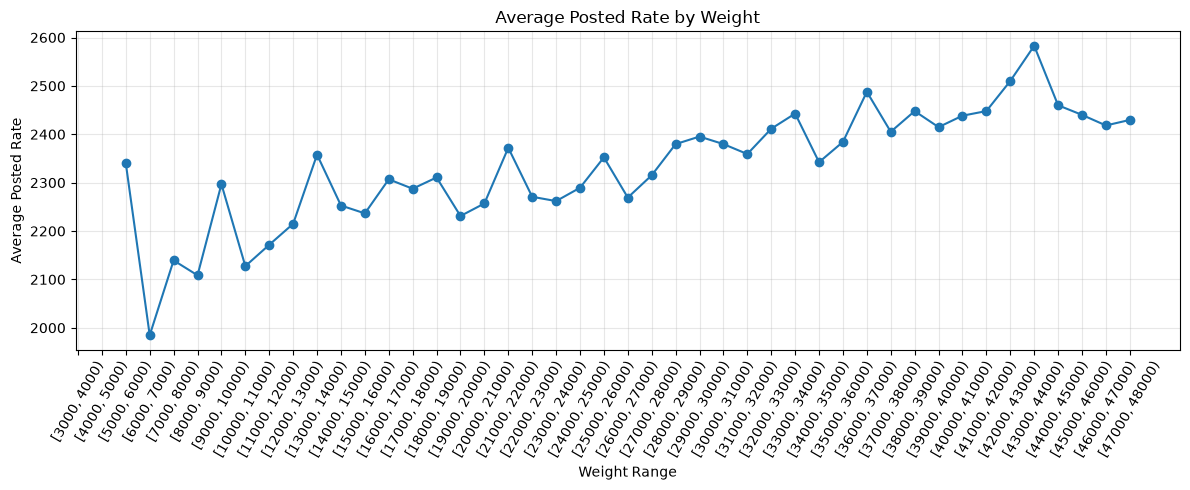

In [198]:
# Compare average posted rate across weight ranges

weight_data = data.copy()

weight_data["weight_range"] = pd.cut(
    weight_data["weight"],
    bins=range(0, int(weight_data["weight"].max()) + 1000, 1000),
    right=False
)

weight_rate = weight_data.groupby(
    "weight_range", observed=False
)["posted_rate"].mean()

plt.figure(figsize=(12, 5))
plt.plot(
    weight_rate.index.astype(str),
    weight_rate.values,
    marker="o"
)

plt.title("Average Posted Rate by Weight")
plt.xlabel("Weight Range")
plt.ylabel("Average Posted Rate")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [199]:
# Compare high-rate loads with the full dataset

data["rate_group"] = data["posted_rate"].apply(
    lambda rate: "High Rate (>= 7000)"
    if rate >= 7000 else "Rate Below 7000"
)

comparison = data.groupby("rate_group")[
    ["posted_rate", "distance", "weight"]
].mean()

display(comparison)

,posted_rate,distance,weight
rate_group,,,
High Rate (>= 7000),11647.011420,1646.988166,31627.840237
Rate Below 7000,2340.943106,1134.124898,31414.598510


In [200]:
# Identify high-distance and high-weight shipments

distance_threshold = data["distance"].quantile(0.75)
weight_threshold = data["weight"].quantile(0.75)

high_loads = data[
    (data["distance"] >= distance_threshold) &
    (data["weight"] >= weight_threshold)
].copy()

print("Distance threshold:", distance_threshold)
print("Weight threshold:", weight_threshold)
print("High-distance and high-weight loads:", len(high_loads))

display(high_loads.head())

Distance threshold: 1645.9
Weight threshold: 37063.0
High-distance and high-weight loads: 2985


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate,rate_group
17,TR-000018,New Orleans,Bakersfield,32.53273,-92.19519,33.28832,-116.67935,1706.0,Dry Van,40439.0,2025-01-01,0.99368,1.88236,3238.08,Rate Below 7000
51,TR-000052,Bakersfield,Mobile,33.28832,-116.67935,31.80442,-88.25195,1922.3,Dry Van,37974.0,2025-01-01,0.95147,1.87015,3658.56,Rate Below 7000
117,TR-000118,Richmond,El Paso,38.09122,-76.78906,33.31075,-110.31230,2223.2,Dry Van,38009.0,2025-01-01,0.98650,1.80907,4091.87,Rate Below 7000
131,TR-000132,Albany,Amarillo,43.96975,-71.05842,33.17137,-104.36789,2251.7,Dry Van,37379.0,2025-01-01,1.00028,1.76503,3982.15,Rate Below 7000
175,TR-000176,Hartford,Los Angeles,39.55328,-72.18051,28.56624,-116.70249,3109.8,Reefer,40154.0,2025-01-02,0.97330,2.01059,6180.45,Rate Below 7000


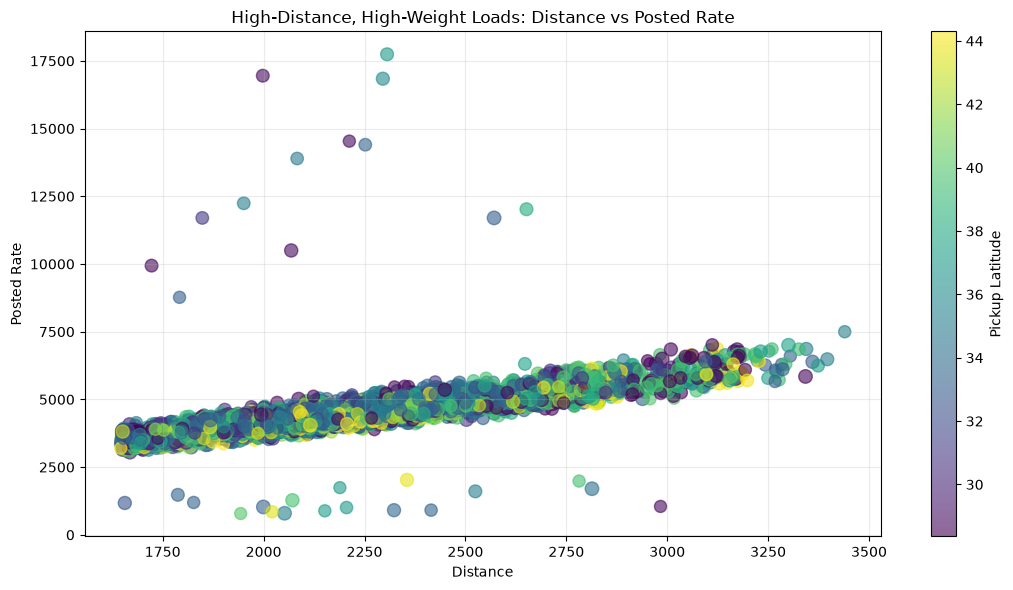

In [201]:
# Keep rows with the values needed for the chart
plot_data = high_loads.dropna(
    subset=["distance", "weight", "posted_rate",
            "pickup_lat", "pickup_lon",
            "delivery_lat", "delivery_lon"]
)

plt.figure(figsize=(11, 6))

scatter = plt.scatter(
    plot_data["distance"],
    plot_data["posted_rate"],
    s=plot_data["weight"] / 500,
    c=plot_data["pickup_lat"],
    alpha=0.6
)

plt.colorbar(scatter, label="Pickup Latitude")
plt.title("High-Distance, High-Weight Loads: Distance vs Posted Rate")
plt.xlabel("Distance")
plt.ylabel("Posted Rate")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [202]:
# Compare rates for repeated routes

route_summary = (
    high_loads.groupby(["pickup", "delivery"])
    .agg(
        load_count=("posted_rate", "size"),
        avg_distance=("distance", "mean"),
        avg_weight=("weight", "mean"),
        avg_rate=("posted_rate", "mean"),
        min_rate=("posted_rate", "min"),
        max_rate=("posted_rate", "max"),
        rate_std=("posted_rate", "std")
    )
    .reset_index()
)

# Routes with at least 2 loads and the largest rate variation
route_summary = route_summary[
    route_summary["load_count"] >= 2
].sort_values("rate_std", ascending=False)

display(route_summary.head(20))

,pickup,delivery,load_count,avg_distance,avg_weight,avg_rate,min_rate,max_rate,rate_std
344,Greensboro,Phoenix,5,2286.800000,41223.200000,6951.900000,4173.86,16841.60,5533.233714
802,San Francisco,Shreveport,2,1968.800000,40769.500000,8374.680000,4508.55,12240.81,5467.533480
432,Lexington,Fresno,7,2302.028571,40835.714286,6494.974286,4390.62,17742.34,4963.833545
620,Phoenix,Jacksonville,4,2189.825000,43114.500000,7139.770000,4156.35,14536.22,4944.775946
629,Phoenix,Nashville,7,1979.342857,42360.857143,5812.615714,3701.01,16951.43,4920.301221
58,Atlanta,Phoenix,9,2075.622222,42247.444444,5302.243333,3951.89,13894.55,3231.755409
312,Fresno,Savannah,5,2540.840000,42155.000000,6262.300000,4634.73,11700.83,3044.819745
889,Tucson,Montgomery,7,1863.100000,39857.857143,5035.225714,3498.42,11700.79,2946.965477
50,Amarillo,Raleigh,3,1798.400000,40199.666667,5735.406667,4172.29,8768.95,2627.534343
771,San Francisco,Baton Rouge,2,2054.200000,42639.500000,2606.680000,795.36,4418.00,2561.593310


Conclusion - The posted rate is mainly influenced by distance and weight. However, we found that loads with similar distance and weight can still have different prices. After further analysis, we found that pickup and delivery locations may also affect the price. In the earlier correlation analysis, latitude and longitude showed little direct relationship with the posted rate, but they may still help the model understand location-based price differences.

##### Distribution Analysis

###### Distribution of categorical features

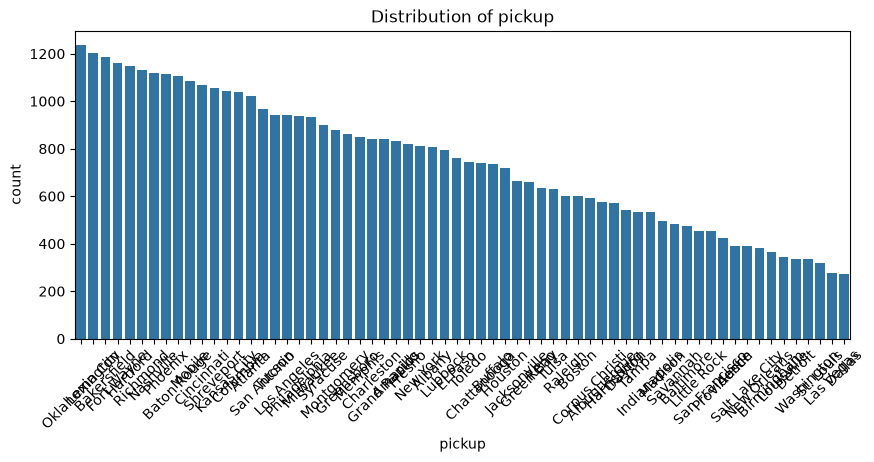

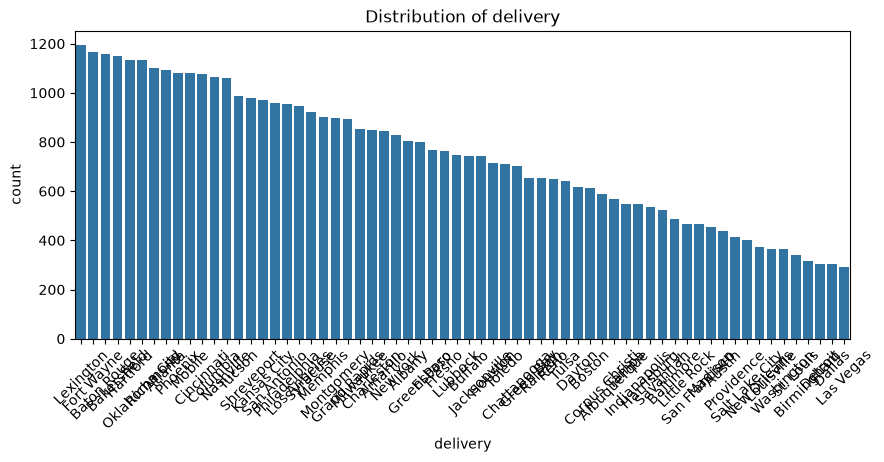

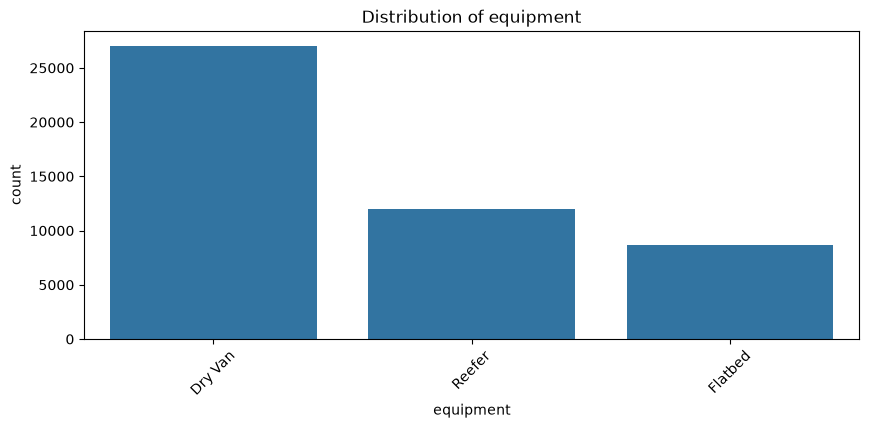

In [203]:
# Distribution of categorical features
categorical_features = ["pickup", "delivery", "equipment"]

for col in categorical_features:
    plt.figure(figsize=(10, 4))
    sns.countplot(data=data, x=col, order=data[col].value_counts().index)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.show()

Equipment distribution between other features

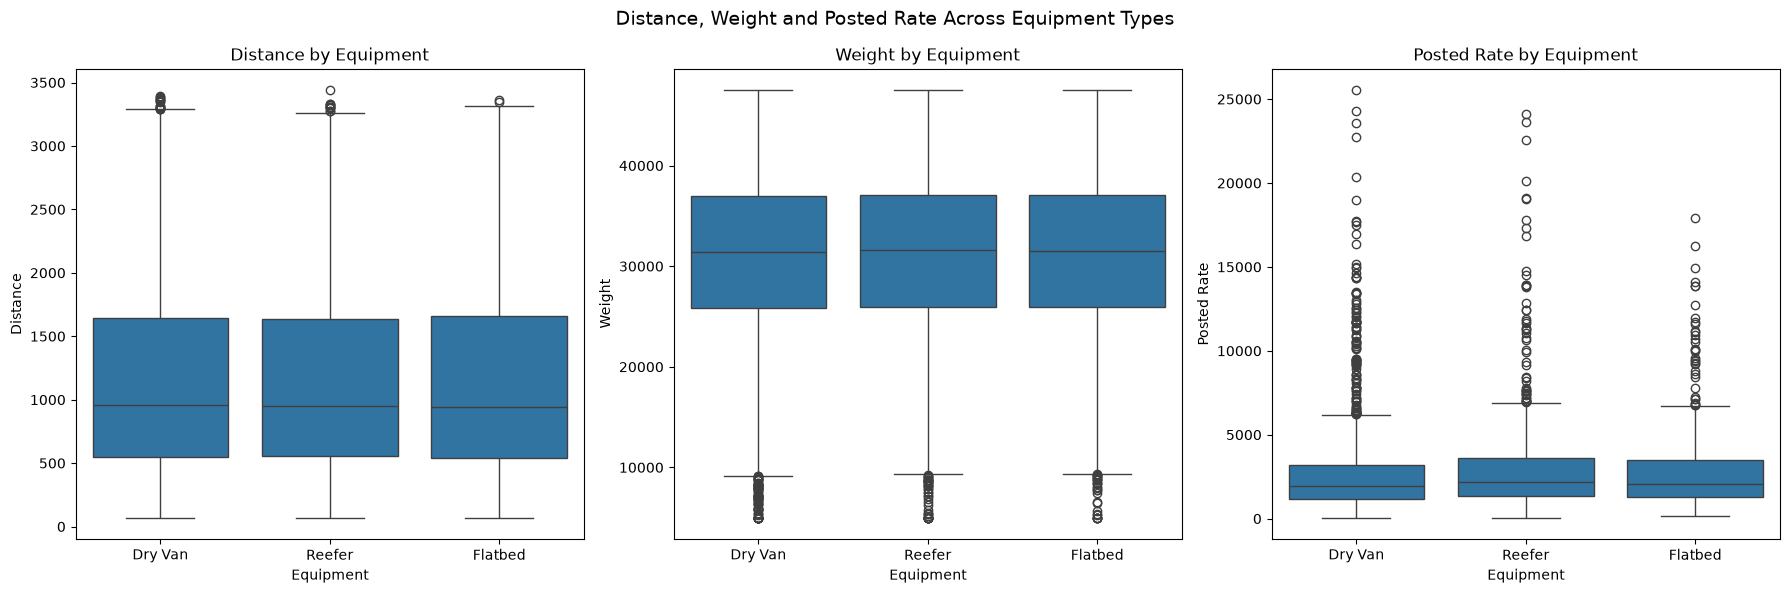

In [204]:
# Compare distance, weight, and posted rate across equipment types

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Distance by equipment
sns.boxplot(data=data, x="equipment", y="distance", ax=axes[0])
axes[0].set_title("Distance by Equipment")
axes[0].set_xlabel("Equipment")
axes[0].set_ylabel("Distance")

# 2. Weight by equipment
sns.boxplot(data=data, x="equipment", y="weight", ax=axes[1])
axes[1].set_title("Weight by Equipment")
axes[1].set_xlabel("Equipment")
axes[1].set_ylabel("Weight")

# 3. Posted rate by equipment
sns.boxplot(data=data, x="equipment", y="posted_rate", ax=axes[2])
axes[2].set_title("Posted Rate by Equipment")
axes[2].set_xlabel("Equipment")
axes[2].set_ylabel("Posted Rate")

plt.suptitle("Distance, Weight and Posted Rate Across Equipment Types", fontsize=14)
plt.tight_layout()
plt.show()

###### Distribution Over time

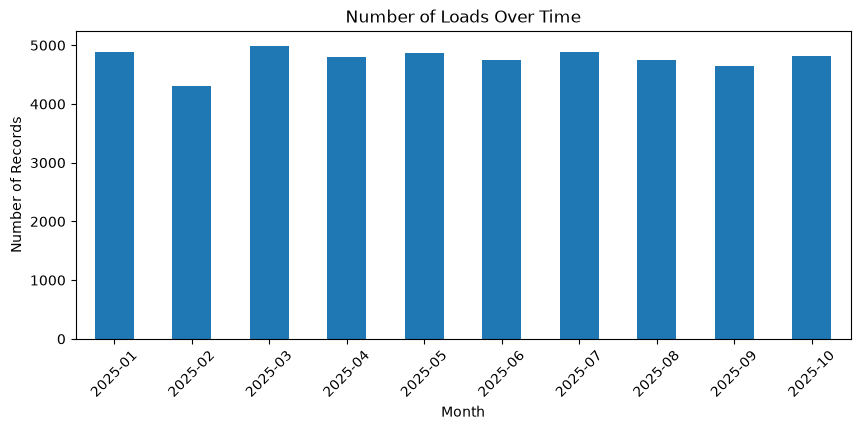

In [205]:
# Distribution of records over time
data["date"] = pd.to_datetime(data["date"])

data.groupby(data["date"].dt.to_period("M")).size().plot(
    kind="bar", figsize=(10, 4)
)

plt.title("Number of Loads Over Time")
plt.xlabel("Month")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.show()

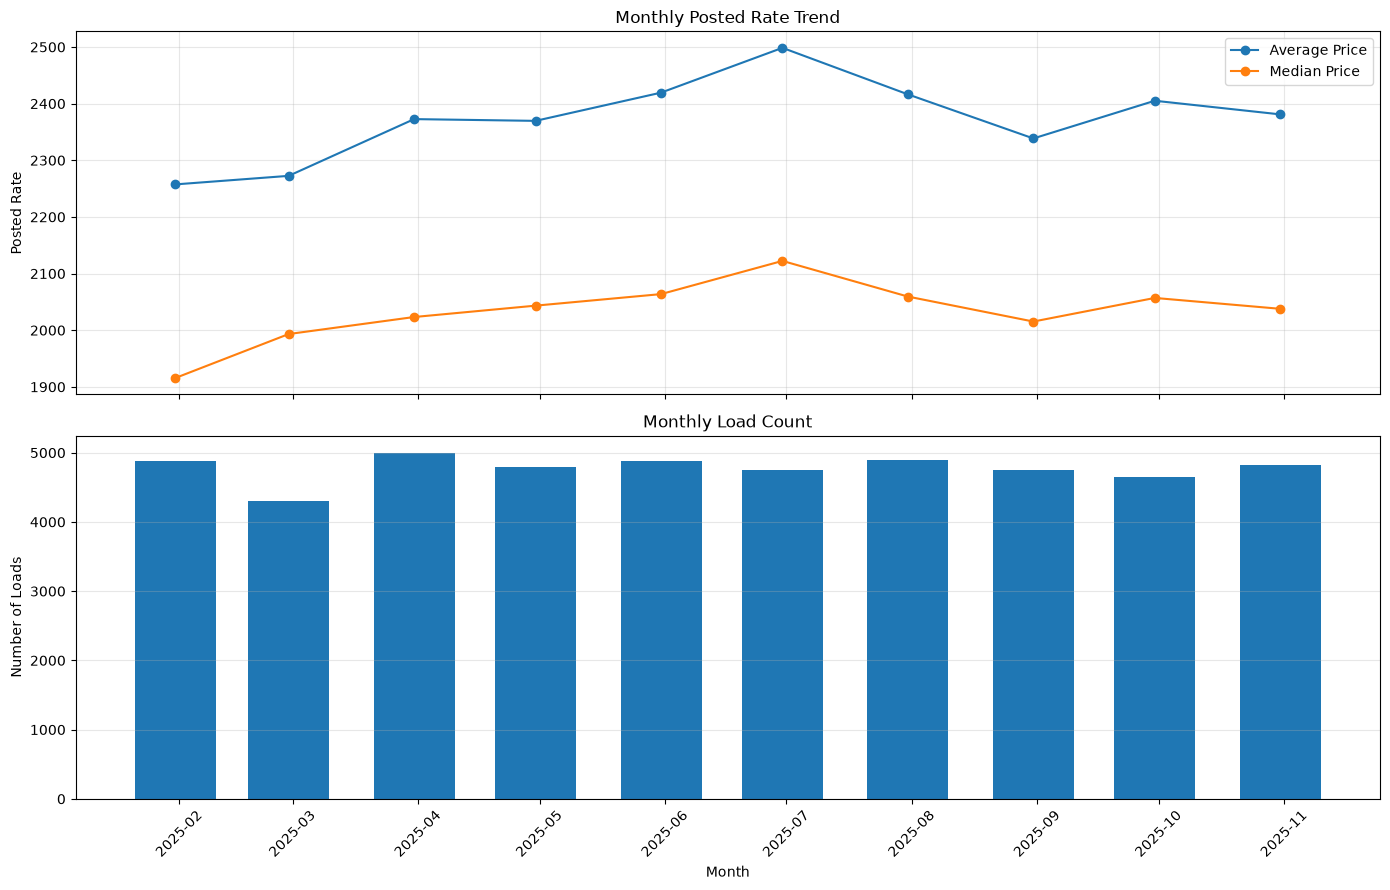

C:\Users\Admin\AppData\Local\Temp\ipykernel_5488\1451508856.py:45: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_data.round(2))


,date,avg_price,median_price,load_count
0,2025-01-31,2257.43,1915.68,4887
1,2025-02-28,2272.51,1993.26,4307
2,2025-03-31,2372.68,2023.32,4996
3,2025-04-30,2369.58,2043.38,4794
4,2025-05-31,2419.40,2063.75,4873
5,2025-06-30,2498.50,2122.36,4753
6,2025-07-31,2416.38,2059.41,4889
7,2025-08-31,2338.54,2015.31,4744
8,2025-09-30,2405.09,2057.00,4644
9,2025-10-31,2381.02,2037.80,4820


In [206]:
# Compare monthly posted rate and load count

data["date"] = pd.to_datetime(data["date"], errors="coerce")

monthly_data = (
    data.dropna(subset=["date", "posted_rate"])
    .set_index("date")
    .resample("ME")
    .agg(
        avg_price=("posted_rate", "mean"),
        median_price=("posted_rate", "median"),
        load_count=("posted_rate", "count")
    )
    .reset_index()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Chart 1: Average and median price
axes[0].plot(
    monthly_data["date"], monthly_data["avg_price"],
    marker="o", label="Average Price"
)
axes[0].plot(
    monthly_data["date"], monthly_data["median_price"],
    marker="o", label="Median Price"
)

axes[0].set_title("Monthly Posted Rate Trend")
axes[0].set_ylabel("Posted Rate")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Chart 2: Number of loads each month
axes[1].bar(monthly_data["date"], monthly_data["load_count"], width=20)
axes[1].set_title("Monthly Load Count")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Number of Loads")
axes[1].grid(axis="y", alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_data.round(2))

The average posted rates in July and August are higher than in the other months, even though the number of loads remains relatively similar. This suggests that factors other than load count may be influencing the prices.

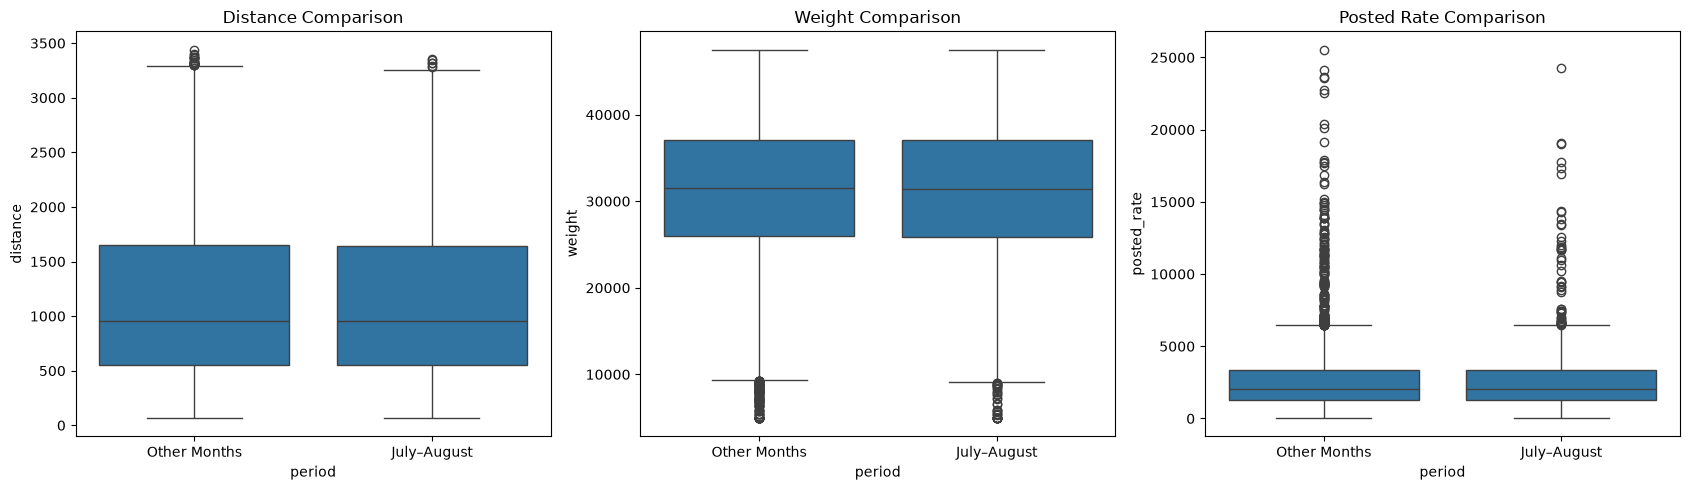

,distance,weight,posted_rate,pickup_lat,pickup_lon,delivery_lat,delivery_lon
period,,,,,,,
July–August,1131.36,31339.81,2378.04,35.68,-90.83,35.61,-90.96
Other Months,1137.10,31434.48,2372.86,35.64,-90.95,35.65,-90.84


In [207]:
# Compare July and August with the rest of the year

data["date"] = pd.to_datetime(data["date"], errors="coerce")

data["period"] = data["date"].dt.month.apply(
    lambda month: "July–August" if month in [7, 8]
    else "Other Months"
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. Compare distance
sns.boxplot(data=data, x="period", y="distance", ax=axes[0])
axes[0].set_title("Distance Comparison")

# 2. Compare weight
sns.boxplot(data=data, x="period", y="weight", ax=axes[1])
axes[1].set_title("Weight Comparison")

# 3. Compare posted rate
sns.boxplot(data=data, x="period", y="posted_rate", ax=axes[2])
axes[2].set_title("Posted Rate Comparison")

plt.tight_layout()
plt.show()

# Compare the average values
display(
    data.groupby("period")[
        ["distance", "weight", "posted_rate",
         "pickup_lat", "pickup_lon",
         "delivery_lat", "delivery_lon"]
    ].mean().round(2)
)

In [208]:
# Compare the most common pickup and delivery locations

for period in ["July–August", "Other Months"]:
    subset = data[data["period"] == period]

    print(f"\n{period} - Top Pickup Locations")
    display(subset["pickup"].value_counts().head(10))

    print(f"\n{period} - Top Delivery Locations")
    display(subset["delivery"].value_counts().head(10))


July–August - Top Pickup Locations


pickup
Nashville        272
Lexington        257
Oklahoma City    251
Fort Wayne       245
Bakersfield      244
Cincinnati       229
Kansas City      227
Phoenix          225
Richmond         222
Mobile           220
Name: count, dtype: int64


July–August - Top Delivery Locations


delivery
Oklahoma City    239
Hartford         237
Baton Rouge      233
Lexington        230
Cincinnati       229
Atlanta          228
Nashville        227
Mobile           226
Fort Wayne       224
Richmond         223
Name: count, dtype: int64


Other Months - Top Pickup Locations


pickup
Oklahoma City    984
Lexington        947
Bakersfield      942
Hartford         927
Fort Wayne       915
Richmond         910
Baton Rouge      904
Phoenix          889
Mobile           866
Shreveport       861
Name: count, dtype: int64


Other Months - Top Delivery Locations


delivery
Lexington        963
Fort Wayne       944
Bakersfield      929
Baton Rouge      924
Hartford         896
Oklahoma City    893
Richmond         878
Phoenix          871
Atlanta          864
Mobile           854
Name: count, dtype: int64

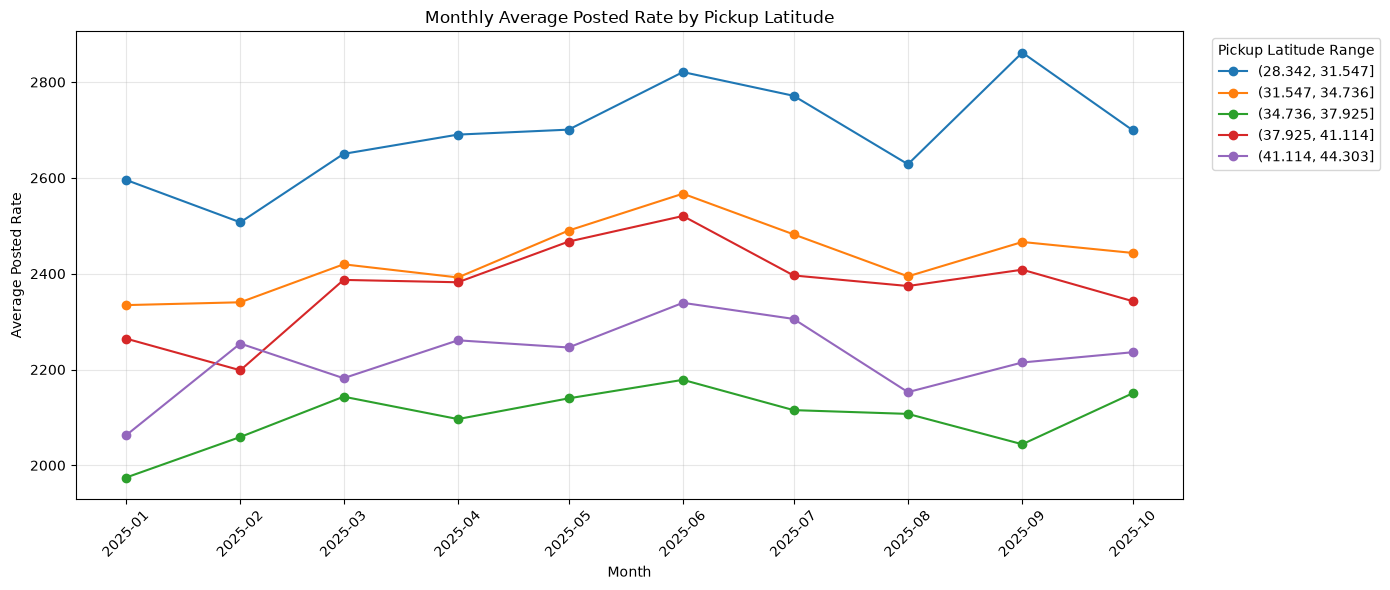

In [209]:
# Compare location-based prices over time

data["date"] = pd.to_datetime(data["date"], errors="coerce")

# Create pickup latitude groups
data["pickup_lat_range"] = pd.cut(data["pickup_lat"], bins=5)

# Group by month and latitude range
monthly_location_price = (
    data.dropna(subset=["date", "pickup_lat_range", "posted_rate"])
    .assign(month=lambda df: df["date"].dt.to_period("M").dt.to_timestamp())
    .groupby(["month", "pickup_lat_range"], observed=True)
    .agg(
        avg_price=("posted_rate", "mean"),
        load_count=("posted_rate", "count")
    )
    .reset_index()
)

# Plot monthly price trends for each latitude range
plt.figure(figsize=(14, 6))

for location_range, group in monthly_location_price.groupby("pickup_lat_range", observed=True):
    plt.plot(
        group["month"],
        group["avg_price"],
        marker="o",
        label=str(location_range)
    )

plt.title("Monthly Average Posted Rate by Pickup Latitude")
plt.xlabel("Month")
plt.ylabel("Average Posted Rate")
plt.legend(title="Pickup Latitude Range", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

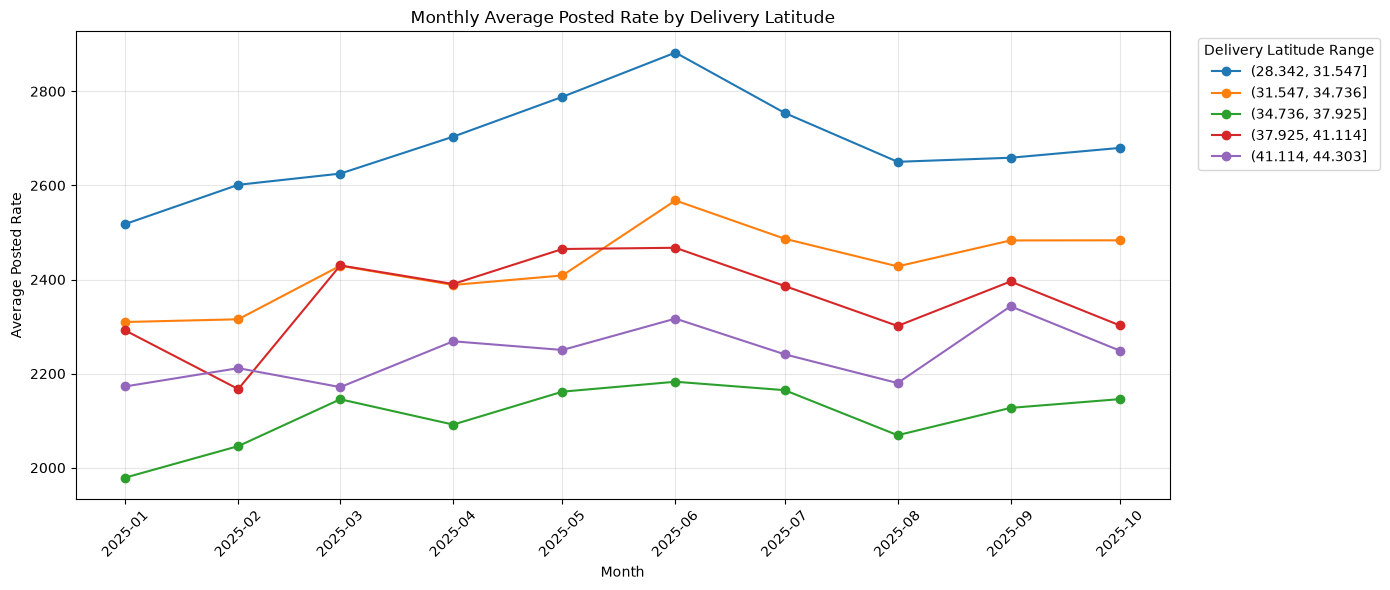

In [210]:
# Compare delivery latitude-based prices over time

data["date"] = pd.to_datetime(data["date"], errors="coerce")

# Group delivery latitudes into 5 geographic ranges
data["delivery_lat_range"] = pd.cut(
    data["delivery_lat"], bins=5
)

# Calculate monthly average price for each delivery latitude range
monthly_delivery_price = (
    data.dropna(subset=["date", "delivery_lat_range", "posted_rate"])
    .assign(month=lambda df: df["date"].dt.to_period("M").dt.to_timestamp())
    .groupby(["month", "delivery_lat_range"], observed=True)
    .agg(
        avg_price=("posted_rate", "mean"),
        load_count=("posted_rate", "count")
    )
    .reset_index()
)

# Plot monthly price trends for each delivery latitude range
plt.figure(figsize=(14, 6))

for location_range, group in monthly_delivery_price.groupby(
    "delivery_lat_range", observed=True
):
    plt.plot(
        group["month"],
        group["avg_price"],
        marker="o",
        label=str(location_range)
    )

plt.title("Monthly Average Posted Rate by Delivery Latitude")
plt.xlabel("Month")
plt.ylabel("Average Posted Rate")
plt.legend(
    title="Delivery Latitude Range",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**The monthly price variation appears to be influenced by pickup and delivery locations, represented by their latitude and longitude. Even though the monthly load counts, distance, and weight show no major differences, the average posted rates increase in certain months. Our location-based analysis suggests that geographical differences between pickup and delivery points may contribute to these price changes. However, further route-level analysis would be needed to confirm this relationship.**

###### Distribution on numerical values

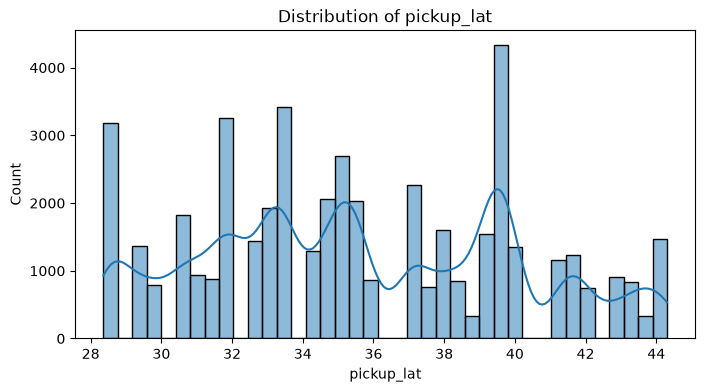

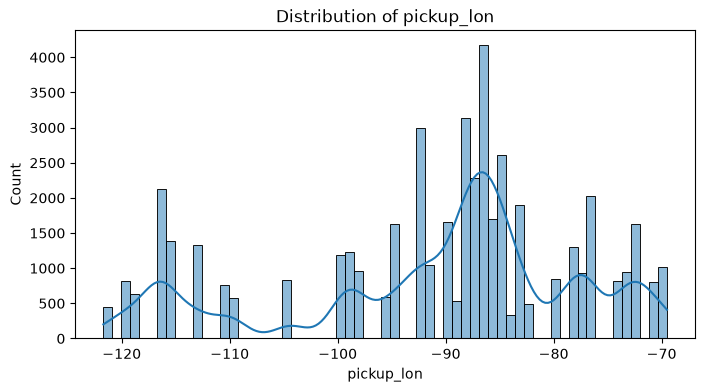

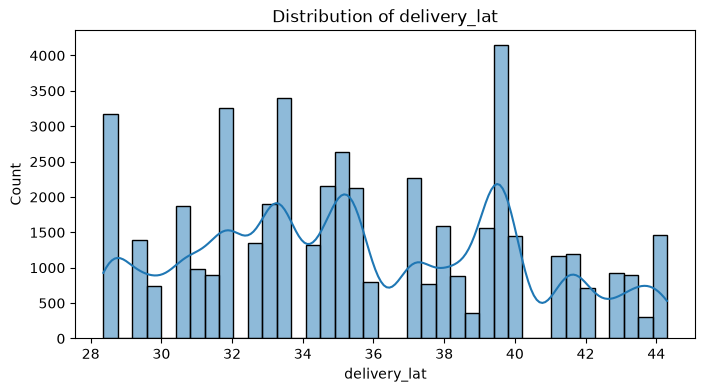

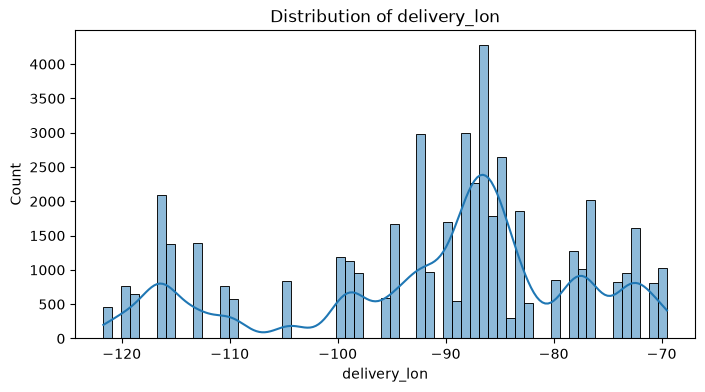

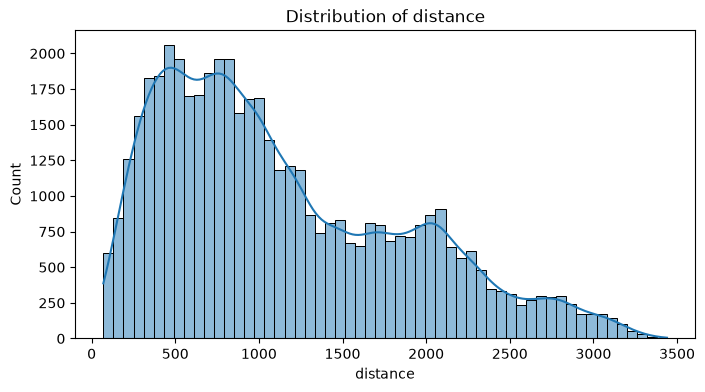

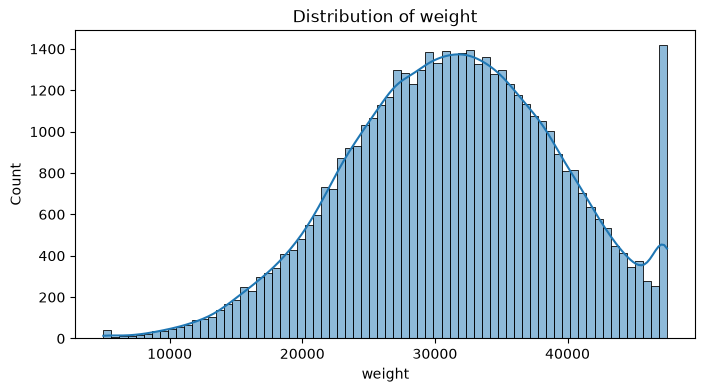

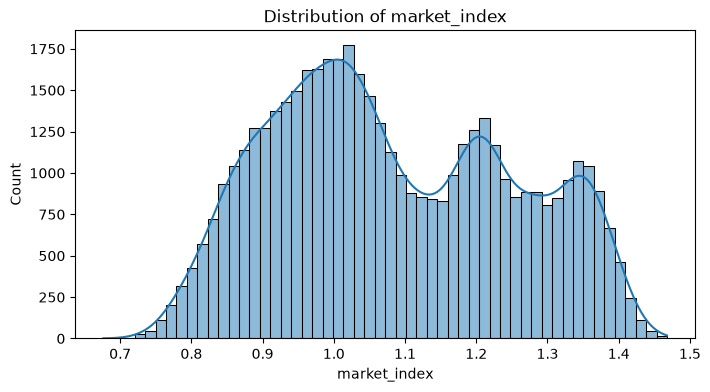

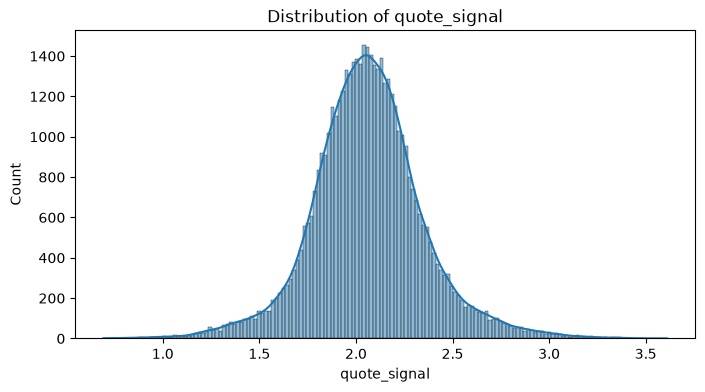

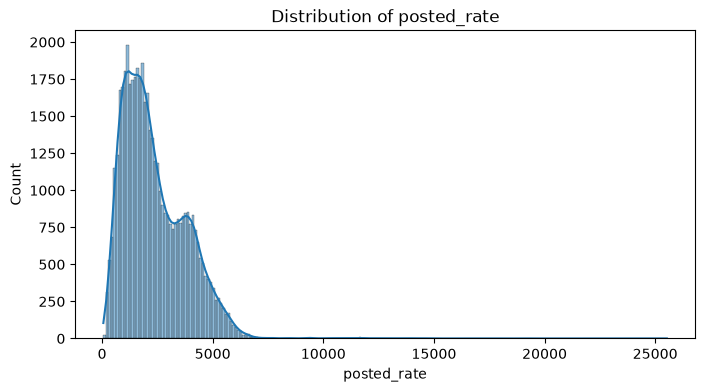

In [211]:
# Distribution of numerical features
numerical_features = data.select_dtypes(include="number")
for col in numerical_features:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=data, x=col, kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

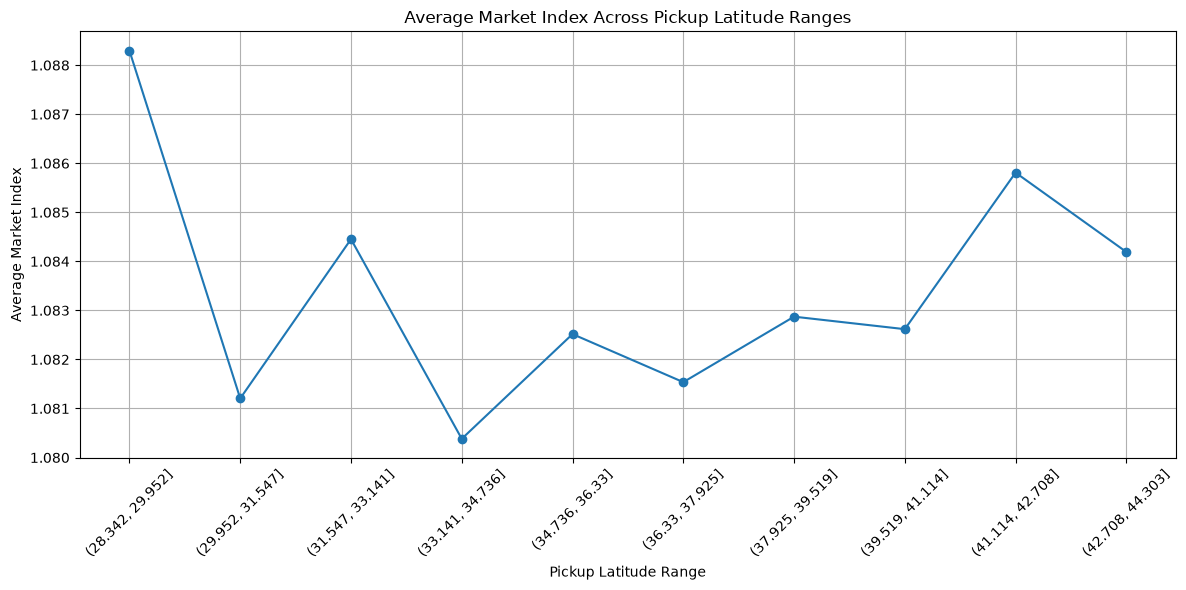

In [212]:
data["pickup_lat_range"] = pd.cut(data["pickup_lat"], bins=10)

location_market = data.groupby("pickup_lat_range", observed=True).agg(
    avg_market_index=("market_index", "mean"),
    load_count=("market_index", "count")
).reset_index()

plt.figure(figsize=(12, 6))
plt.plot(location_market["pickup_lat_range"].astype(str),
         location_market["avg_market_index"], marker="o")

plt.title("Average Market Index Across Pickup Latitude Ranges")
plt.xlabel("Pickup Latitude Range")
plt.ylabel("Average Market Index")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

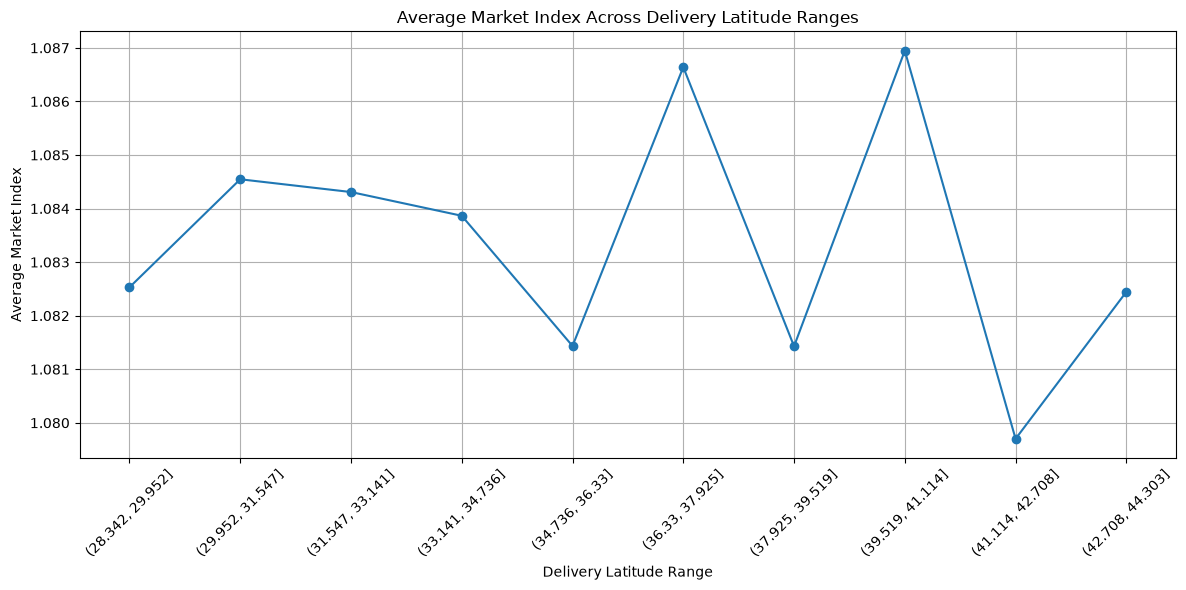

In [213]:
data["delivery_lat_range"] = pd.cut(data["delivery_lat"], bins=10)

location_market = data.groupby("delivery_lat_range", observed=True).agg(
    avg_market_index=("market_index", "mean"),
    load_count=("market_index", "count")
).reset_index()

plt.figure(figsize=(12, 6))
plt.plot(location_market["delivery_lat_range"].astype(str),
         location_market["avg_market_index"], marker="o")

plt.title("Average Market Index Across Delivery Latitude Ranges")
plt.xlabel("Delivery Latitude Range")
plt.ylabel("Average Market Index")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

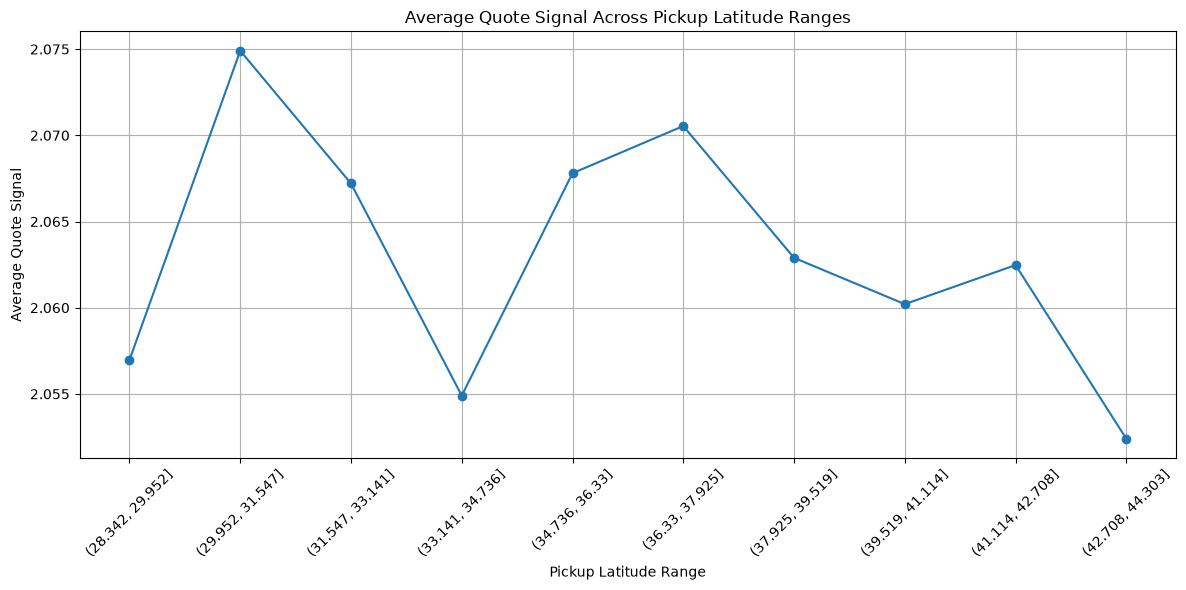

In [214]:
data["pickup_lat_range"] = pd.cut(data["pickup_lat"], bins=10)

location_quote = data.groupby("pickup_lat_range", observed=True).agg(
    avg_quote_signal=("quote_signal", "mean"),
    load_count=("quote_signal", "count")
).reset_index()

plt.figure(figsize=(12, 6))
plt.plot(location_quote["pickup_lat_range"].astype(str),
         location_quote["avg_quote_signal"], marker="o")

plt.title("Average Quote Signal Across Pickup Latitude Ranges")
plt.xlabel("Pickup Latitude Range")
plt.ylabel("Average Quote Signal")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

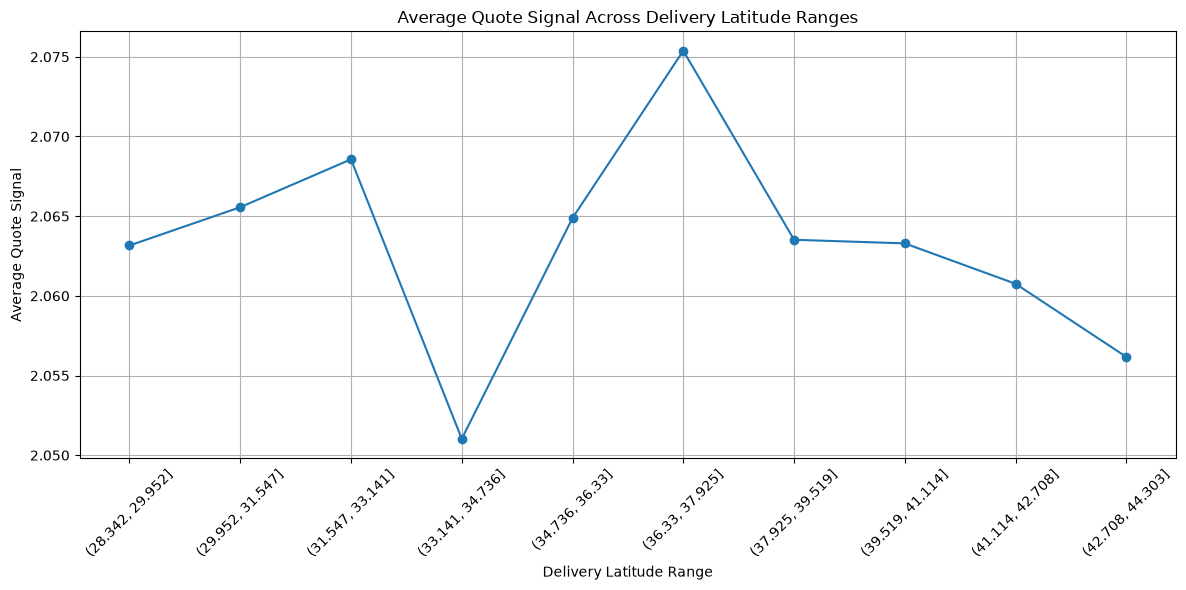

In [215]:
data["delivery_lat_range"] = pd.cut(data["delivery_lat"], bins=10)

location_quote = data.groupby("delivery_lat_range", observed=True).agg(
    avg_quote_signal=("quote_signal", "mean"),
    load_count=("quote_signal", "count")
).reset_index()

plt.figure(figsize=(12, 6))
plt.plot(location_quote["delivery_lat_range"].astype(str),
         location_quote["avg_quote_signal"], marker="o")

plt.title("Average Quote Signal Across Delivery Latitude Ranges")
plt.xlabel("Delivery Latitude Range")
plt.ylabel("Average Quote Signal")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

##### Most & Least Analysis

Most and Least frequent location for pick up

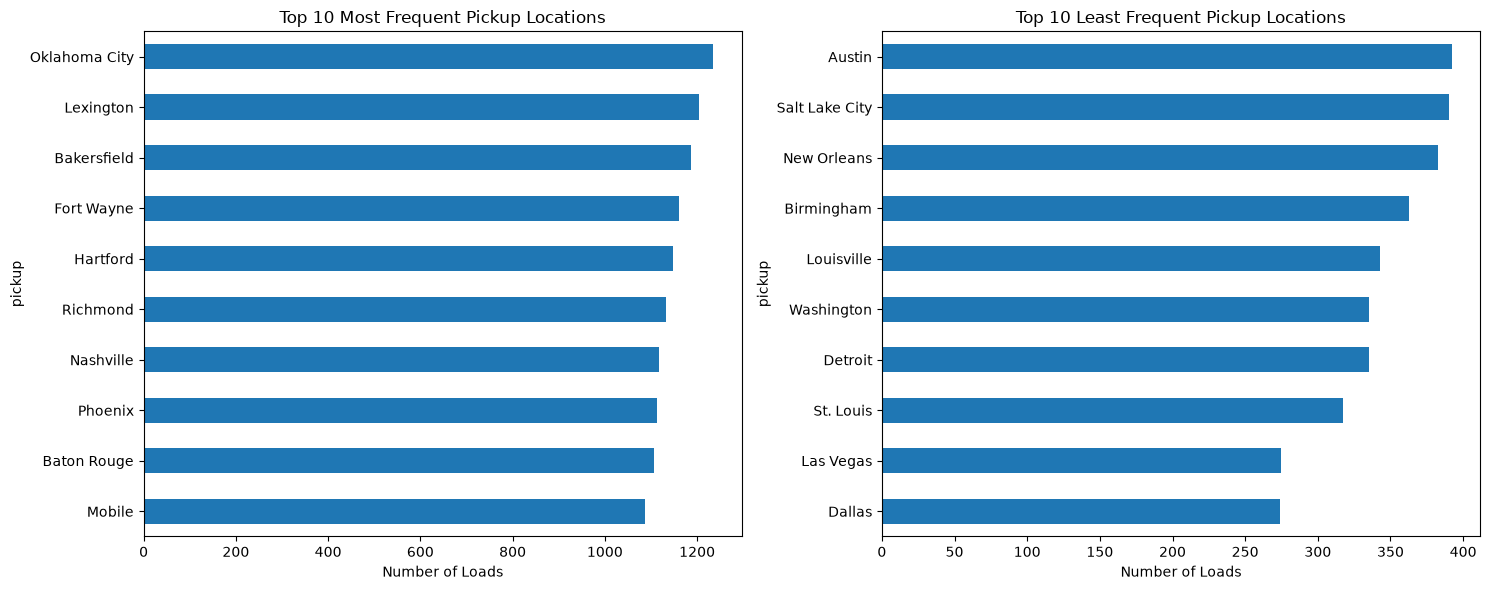

In [216]:
pickup_counts = data["pickup"].value_counts()

top_10 = pickup_counts.head(10)
bottom_10 = pickup_counts.tail(10).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top_10.sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Top 10 Most Frequent Pickup Locations")
axes[0].set_xlabel("Number of Loads")

bottom_10.plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 10 Least Frequent Pickup Locations")
axes[1].set_xlabel("Number of Loads")

plt.tight_layout()
plt.show()

Most and Least frequent location for Delivery up

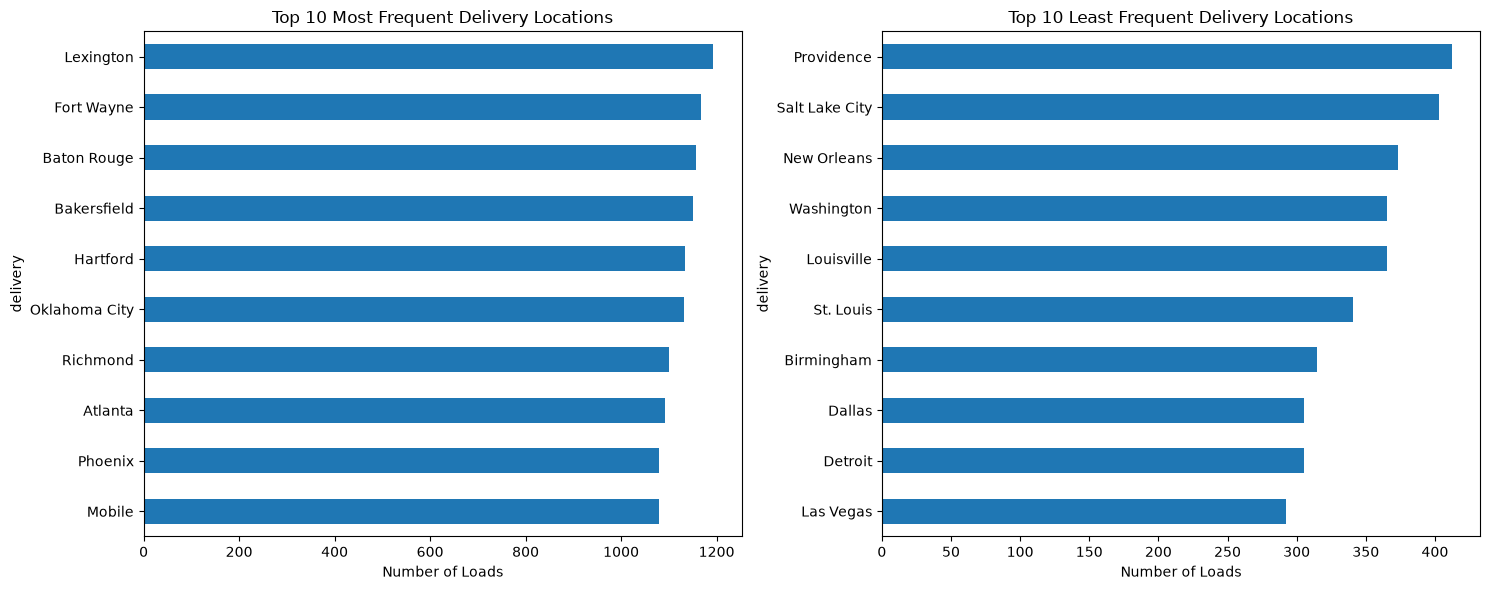

In [217]:
delivery_counts = data["delivery"].value_counts()

top_10 = delivery_counts.head(10)
bottom_10 = delivery_counts.tail(10).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top_10.sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Top 10 Most Frequent Delivery Locations")
axes[0].set_xlabel("Number of Loads")

bottom_10.plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 10 Least Frequent Delivery Locations")
axes[1].set_xlabel("Number of Loads")

plt.tight_layout()
plt.show()

##### Target Variable vs Feature Analysis

Based on the initial EDA, we observed that distance appears to have a direct relationship with the target variable, posted_rate, with longer distances generally associated with higher rates.

The geographical features - pickup_lat, pickup_lon, delivery_lat, and delivery_lon - may also contribute to variations in the posted rate by capturing location-based differences.

In the next stage, we will further investigate the relationship between posted_rate and the remaining features:
weight,
market_index,
quote_signal
This analysis will help us better understand how these features relate to the target variable

Weight

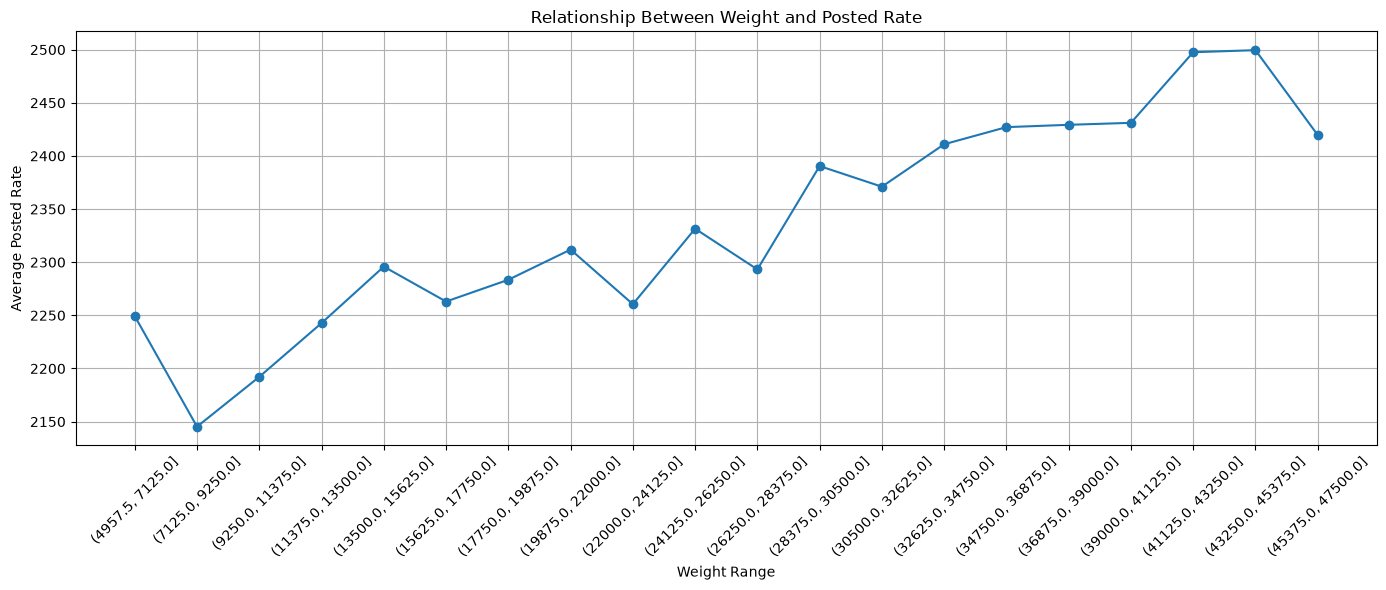

In [218]:
# Divide weight into 20 ranges
data["weight_range"] = pd.cut(data["weight"], bins=20)

# Calculate average posted rate and load count
weight_price = data.groupby("weight_range", observed=True).agg(
    avg_price=("posted_rate", "mean"),
    load_count=("posted_rate", "count")
).reset_index()

# Plot the line chart
plt.figure(figsize=(14, 6))
plt.plot(
    weight_price["weight_range"].astype(str),
    weight_price["avg_price"],
    marker="o"
)

plt.title("Relationship Between Weight and Posted Rate")
plt.xlabel("Weight Range")
plt.ylabel("Average Posted Rate")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [219]:
data.groupby(pd.cut(data["weight"], bins=10), observed=True).agg(
    avg_weight=("weight", "mean"),
    avg_price=("posted_rate", "mean"),
    median_price=("posted_rate", "median"),
    count=("posted_rate", "count")
).round(2)

,avg_weight,avg_price,median_price,count
weight,,,,
"(4957.5, 9250.0]",7156.53,2191.87,1841.34,154
"(9250.0, 13500.0]",11795.07,2224.77,1892.90,490
"(13500.0, 17750.0]",15957.58,2275.65,1976.82,1582
"(17750.0, 22000.0]",20160.63,2300.56,1973.92,3545
"(22000.0, 26250.0]",24285.37,2300.06,1971.18,6676
"(26250.0, 30500.0]",28419.74,2343.42,2003.26,8992
"(30500.0, 34750.0]",32599.91,2390.70,2034.47,9507
"(34750.0, 39000.0]",36770.81,2428.10,2096.49,7963
"(39000.0, 43250.0]",40911.10,2459.11,2093.05,4969


Market Index

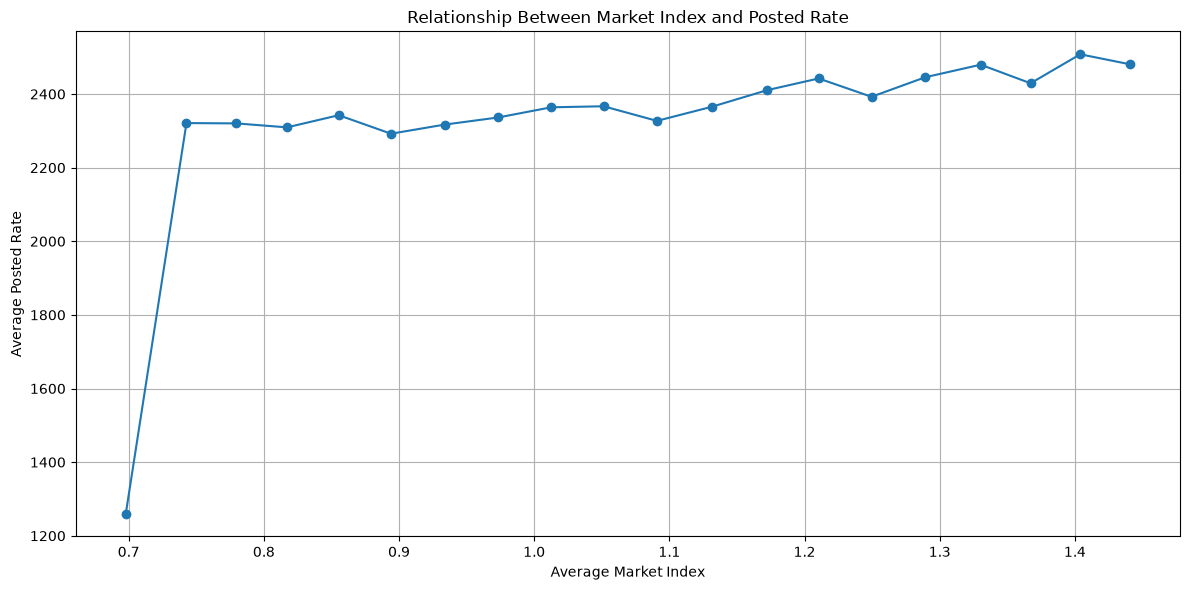

In [220]:
# Divide market index into 20 ranges
data["market_index_range"] = pd.cut(data["market_index"], bins=20)

# Calculate average posted rate and load count
market_price = data.groupby("market_index_range", observed=True).agg(
    avg_market_index=("market_index", "mean"),
    avg_price=("posted_rate", "mean"),
    count=("posted_rate", "count")
).reset_index()

# Plot the line chart
plt.figure(figsize=(12, 6))
plt.plot(
    market_price["avg_market_index"],
    market_price["avg_price"],
    marker="o"
)

plt.title("Relationship Between Market Index and Posted Rate")
plt.xlabel("Average Market Index")
plt.ylabel("Average Posted Rate")
plt.grid(True)
plt.tight_layout()
plt.show()

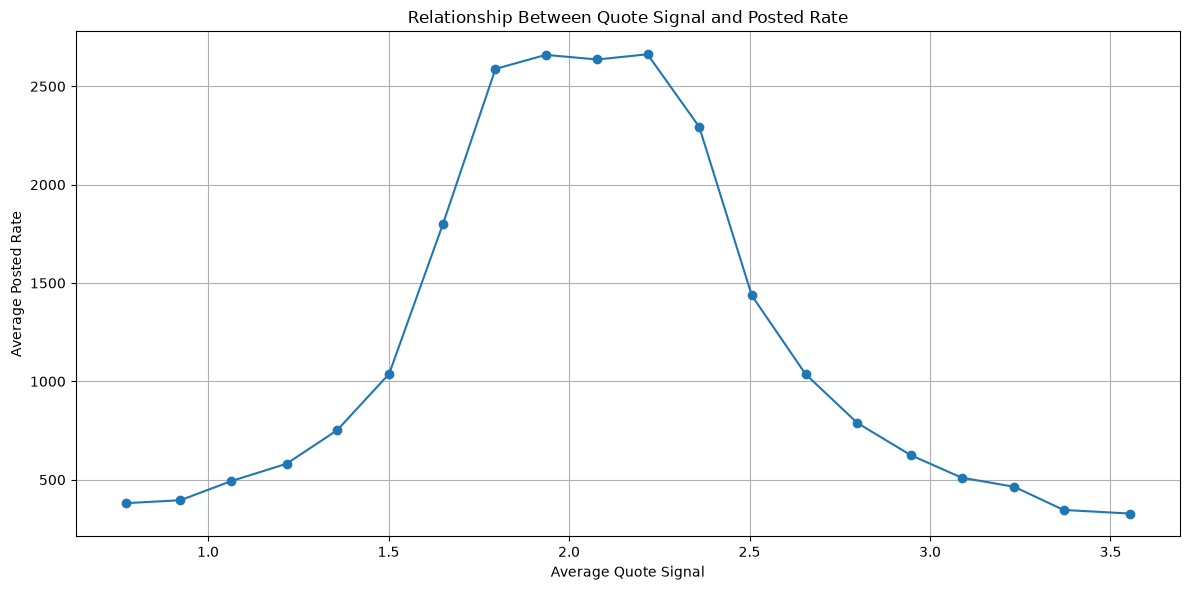

In [221]:
# Divide quote signal into 20 ranges
data["quote_signal_range"] = pd.cut(data["quote_signal"], bins=20)

# Calculate average quote signal, average price, and load count
quote_price = data.groupby("quote_signal_range", observed=True).agg(
    avg_quote_signal=("quote_signal", "mean"),
    avg_price=("posted_rate", "mean"),
    count=("posted_rate", "count")
).reset_index()

# Plot the line chart
plt.figure(figsize=(12, 6))
plt.plot(
    quote_price["avg_quote_signal"],
    quote_price["avg_price"],
    marker="o"
)

plt.title("Relationship Between Quote Signal and Posted Rate")
plt.xlabel("Average Quote Signal")
plt.ylabel("Average Posted Rate")
plt.grid(True)
plt.tight_layout()
plt.show()

The market_index also appears to have some relationship with posted_rate, so we will retain it as a feature for model training and evaluate its contribution during validation

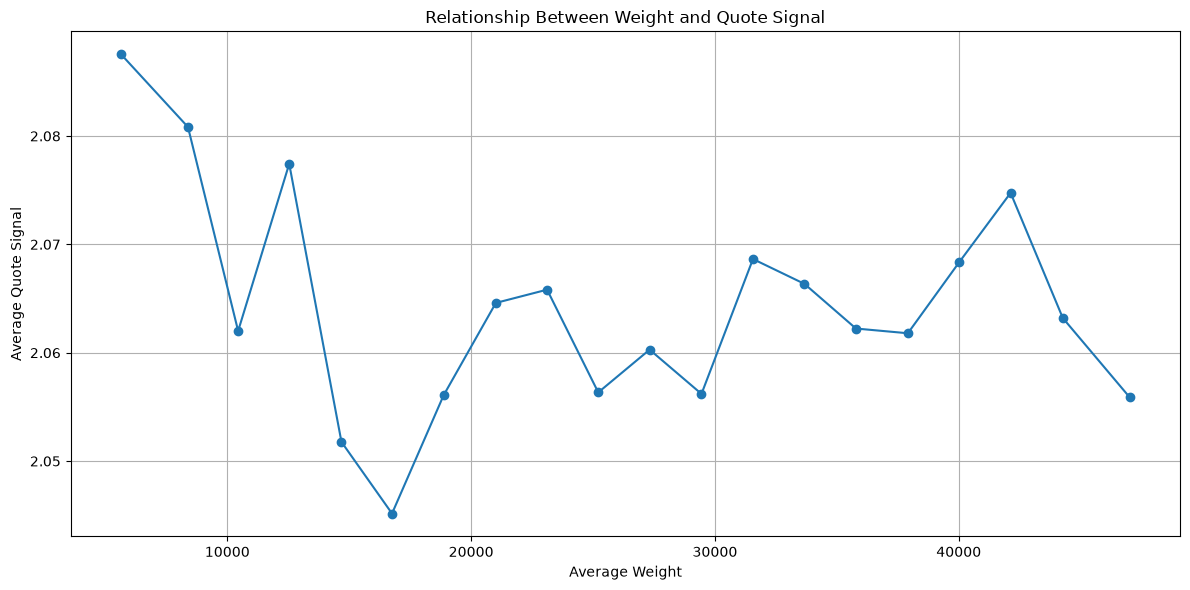

In [222]:
# Divide weight into 20 ranges
data["weight_range"] = pd.cut(data["weight"], bins=20)

# Calculate average quote signal for each weight range
quote_weight = data.groupby("weight_range", observed=True).agg(
    avg_weight=("weight", "mean"),
    avg_quote_signal=("quote_signal", "mean"),
    count=("quote_signal", "count")
).reset_index()

# Plot line chart
plt.figure(figsize=(12, 6))
plt.plot(
    quote_weight["avg_weight"],
    quote_weight["avg_quote_signal"],
    marker="o"
)

plt.title("Relationship Between Weight and Quote Signal")
plt.xlabel("Average Weight")
plt.ylabel("Average Quote Signal")
plt.grid(True)
plt.tight_layout()
plt.show()

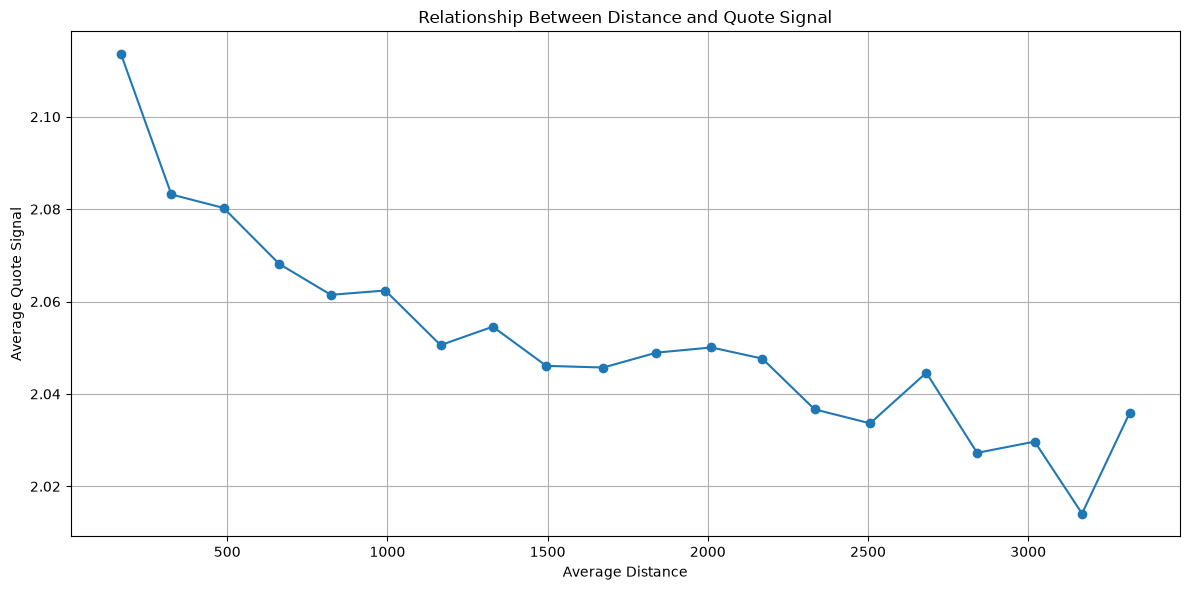

In [223]:
# Divide distance into 20 ranges
data["distance_range"] = pd.cut(data["distance"], bins=20)

# Calculate average quote signal for each distance range
quote_distance = data.groupby("distance_range", observed=True).agg(
    avg_distance=("distance", "mean"),
    avg_quote_signal=("quote_signal", "mean"),
    count=("quote_signal", "count")
).reset_index()

# Plot line chart
plt.figure(figsize=(12, 6))
plt.plot(
    quote_distance["avg_distance"],
    quote_distance["avg_quote_signal"],
    marker="o"
)

plt.title("Relationship Between Distance and Quote Signal")
plt.xlabel("Average Distance")
plt.ylabel("Average Quote Signal")
plt.grid(True)
plt.tight_layout()
plt.show()

Based on the initial analysis, quote_signal appears to have a non-linear relationship with posted_rate and a possible relationship with distance. Since distance is an important pricing-related feature, quote_signal may provide additional useful information to the prediction model

Based on our EDA, we have selected the following features for the initial model training:

distance

pickup_lat

pickup_lon

delivery_lat

delivery_lon

weight

market_index

quote_signal

equipment

pickup

delivery

### Model Training/Testing and Evaluation

#### Desicion Tree 

In [224]:

# Convert date into datetime format
data["date"] = pd.to_datetime(data["date"], errors="coerce")

# Create date-based features
data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.month
data["day"] = data["date"].dt.day
data["day_of_week"] = data["date"].dt.dayofweek

# Select the features used by the model
selected_features = [
    "distance",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "weight",
    "market_index",
    "quote_signal",
    "equipment",
    "pickup",
    "delivery",
    "year",
    "month",
    "day",
    "day_of_week"
]

decision_tree_data = data[selected_features + ["posted_rate"]].copy()

print("Dataset shape:", decision_tree_data.shape)
decision_tree_data.head()


Dataset shape: (47707, 16)


,distance,pickup_lat,pickup_lon,delivery_lat,delivery_lon,weight,market_index,quote_signal,equipment,pickup,delivery,year,month,day,day_of_week,posted_rate
0,274.3,38.09122,-76.78906,38.16908,-72.74564,30658.0,0.95684,2.39595,Dry Van,Richmond,Baltimore,2025,1,1,2,645.41
1,280.5,38.09122,-76.78906,39.22317,-72.96710,17555.0,0.97623,2.43355,Reefer,Richmond,Philadelphia,2025,1,1,2,679.97
2,967.8,39.22317,-72.96710,44.30296,-87.52871,31721.0,1.00971,1.84491,Dry Van,Philadelphia,Green Bay,2025,1,1,2,1802.54
3,965.4,39.55328,-72.18051,34.84933,-86.28940,32333.0,0.94518,1.87712,Dry Van,Hartford,Atlanta,2025,1,1,2,1827.28
4,541.9,31.83025,-94.38343,35.29479,-88.08915,35183.0,0.98480,2.56300,Reefer,Dallas,Nashville,2025,1,1,2,1380.28


In [225]:
# Separate numerical and categorical features

numerical_features = [
    "distance",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "weight",
    "market_index",
    "quote_signal",
    "year",
    "month",
    "day",
    "day_of_week"
]

categorical_features = [
    "equipment",
    "pickup",
    "delivery"
]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)


Numerical features: ['distance', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'weight', 'market_index', 'quote_signal', 'year', 'month', 'day', 'day_of_week']
Categorical features: ['equipment', 'pickup', 'delivery']


In [226]:
# Convert date into datetime format
data["date"] = pd.to_datetime(data["date"], errors="coerce")

# Create date-based features
data["year"] = data["date"].dt.year
data["month"] = data["date"].dt.month
data["day"] = data["date"].dt.day
data["day_of_week"] = data["date"].dt.dayofweek

# Update selected features
selected_features = [
    "distance",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "weight",
    "market_index",
    "quote_signal",
    "equipment",
    "pickup",
    "delivery",
    "year",
    "month",
    "day",
    "day_of_week"
]

decision_tree_data = data[selected_features + ["posted_rate"]].copy()

In [227]:
# Input features
X = decision_tree_data[selected_features].copy()

# Target variable
y = decision_tree_data["posted_rate"].copy()

In [228]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (38165, 15)
Testing data: (9542, 15)


In [229]:
# Process numerical features
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Process categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each column group
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [230]:
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['distance','pickup_lat','pickup_lon',...,'month','day','day_of_week']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsi

In [231]:
# Predict posted rates for the test data
y_pred = decision_tree_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

# Display the results
print("Decision Tree Model Evaluation")
print("-------------------------------")
print(f"MAE:  ${mae:.2f}")
print(f"RMSE: ${rmse:.2f}")
print(f"R² Score: {r2:.4f}")

Decision Tree Model Evaluation
-------------------------------
MAE:  $164.26
RMSE: $849.20
R² Score: 0.6545


In [232]:
# Compare actual and predicted values
comparison = pd.DataFrame({
    "Actual Rate": y_test,
    "Predicted Rate": y_pred
})

comparison["Error"] = comparison["Actual Rate"] - comparison["Predicted Rate"]

comparison.head(10)

,Actual Rate,Predicted Rate,Error
44856,3693.98,3453.25,240.73
15133,2361.76,2384.07,-22.31
22955,1752.97,1811.77,-58.80
38341,4870.06,5152.02,-281.96
27502,3519.22,3558.18,-38.96
15958,4601.77,4516.61,85.16
7242,4860.87,1020.70,3840.17
45179,2903.70,2966.79,-63.09
40313,2044.98,2020.05,24.93
33993,1119.16,1096.66,22.50


In [233]:
# Compare actual and predicted rates
error_analysis = X_test.copy()

error_analysis["actual_rate"] = y_test
error_analysis["predicted_rate"] = y_pred

error_analysis["absolute_error"] = (
    error_analysis["actual_rate"] - error_analysis["predicted_rate"]
).abs()

# Display the 10 largest prediction errors
error_analysis.sort_values(
    by="absolute_error",
    ascending=False
).head(10)

,distance,pickup_lat,pickup_lon,delivery_lat,delivery_lon,weight,market_index,quote_signal,equipment,pickup,delivery,year,month,day,day_of_week,actual_rate,predicted_rate,absolute_error
43307,2801.8,33.28832,-116.67935,40.00674,-73.79840,30399.0,0.88411,2.14923,Reefer,Bakersfield,New York,2025,10,1,2,5510.91,24140.21,18629.30
20089,2470.2,30.92733,-113.23037,35.37376,-77.47605,23108.0,1.37593,2.28344,Dry Van,Tucson,Raleigh,2025,5,7,2,4652.32,22755.66,18103.34
40171,2283.4,31.37602,-86.10743,33.07921,-119.79528,32447.0,0.98502,1.93645,Dry Van,Montgomery,Fresno,2025,9,11,3,20361.89,4259.95,16101.94
41308,1933.1,38.16908,-72.74564,29.39553,-99.69780,33230.0,0.99620,2.12640,Flatbed,Baltimore,Austin,2025,9,18,3,4087.21,20132.37,16045.16
35436,2153.5,33.28832,-116.67935,36.99152,-84.99876,35912.0,0.97071,1.80580,Dry Van,Bakersfield,Lexington,2025,8,12,1,4163.04,17772.53,13609.49
45717,2342.8,41.97663,-84.45902,33.07921,-119.79528,42581.0,1.00650,2.29065,Dry Van,Toledo,Fresno,2025,10,17,4,4374.08,17742.34,13368.26
9496,2255.4,35.98195,-82.78379,28.75668,-115.87725,37735.0,1.01689,1.95222,Flatbed,Greensboro,Phoenix,2025,3,2,6,4401.27,16841.60,12440.33
21609,1421.3,35.39918,-109.59792,39.62180,-88.48008,27841.0,1.23694,2.04142,Flatbed,Albuquerque,Milwaukee,2025,5,17,5,14079.19,3089.75,10989.44
46129,2396.2,31.37602,-86.10743,35.19670,-121.69849,16065.0,0.82852,2.38842,Dry Van,Montgomery,San Francisco,2025,10,19,6,4196.79,15165.13,10968.34
18632,1415.5,44.30296,-87.52871,29.39553,-99.69780,23769.0,1.23850,2.22320,Dry Van,Green Bay,Austin,2025,4,28,0,2749.83,13026.22,10276.39


Model Complexity chexking

In [234]:
tree = decision_tree_model.named_steps["model"]

print("Tree depth:", tree.get_depth())
print("Number of leaves:", tree.get_n_leaves())

Tree depth: 37
Number of leaves: 38148


In [235]:
# Calculate the 98th percentile of posted_rate
rate_threshold = data["posted_rate"].quantile(0.98)

print("98th percentile threshold:", rate_threshold)
print("Records above threshold:", (data["posted_rate"] > rate_threshold).sum())

98th percentile threshold: 5583.4792
Records above threshold: 955


In [236]:
# Review unusually high posted rates
high_rate_records = data[
    data["posted_rate"] > rate_threshold
].sort_values("posted_rate", ascending=False)

high_rate_records[
    ["distance", "weight", "equipment", "pickup", "delivery", "posted_rate"]
].head(20)

,distance,weight,equipment,pickup,delivery,posted_rate
12184,2829.8,33153.0,Dry Van,Bakersfield,Hartford,25533.00
37764,2810.9,33674.0,Dry Van,Phoenix,Syracuse,24294.98
1466,2786.0,30322.0,Reefer,Los Angeles,Syracuse,24140.21
17371,2777.6,33158.0,Reefer,Reno,Philadelphia,23662.71
26235,2552.5,25665.0,Dry Van,Charleston,Phoenix,23580.42
28219,2423.3,30972.0,Dry Van,Tucson,Raleigh,22755.66
3353,2527.9,36840.0,Reefer,Phoenix,Charleston,22534.65
40171,2283.4,32447.0,Dry Van,Montgomery,Fresno,20361.89
40096,1760.3,29521.0,Reefer,Baltimore,Oklahoma City,20132.37
47298,2979.1,30585.0,Reefer,Boston,Bakersfield,19110.30


The model performed reasonably well overall, but some unusual high-rate records caused large prediction errors because the Decision Tree struggled to identify the patterns behind these cases.

#### Decision Tree #2 – Training After 98th Percentile Filtering

In [237]:
# Calculate the 98th percentile using training targets only
rate_threshold = y_train.quantile(0.98)

print("98th percentile threshold:", round(rate_threshold, 2))

98th percentile threshold: 5602.34


In [238]:
# Keep training records at or below the threshold
train_mask = y_train <= rate_threshold

X_train_filtered = X_train.loc[train_mask].copy()
y_train_filtered = y_train.loc[train_mask].copy()

print("Original training rows:", len(X_train))
print("Filtered training rows:", len(X_train_filtered))
print("Rows removed:", len(X_train) - len(X_train_filtered))

Original training rows: 38165
Filtered training rows: 37401
Rows removed: 764


In [239]:
# Create the second Decision Tree model
decision_tree_model_2 = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

# Train using the filtered training data
decision_tree_model_2.fit(X_train_filtered, y_train_filtered)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['distance','pickup_lat','pickup_lon',...,'month','day','day_of_week']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsi

In [240]:
# Predict on the original, unchanged test set
y_pred_2 = decision_tree_model_2.predict(X_test)

# Calculate evaluation metrics
mae_2 = mean_absolute_error(y_test, y_pred_2)
rmse_2 = mean_squared_error(y_test, y_pred_2) ** 0.5
r2_2 = r2_score(y_test, y_pred_2)

print("Decision Tree #2 – After 98th Percentile Filtering")
print("--------------------------------------------------")
print(f"MAE:  ${mae_2:.2f}")
print(f"RMSE: ${rmse_2:.2f}")
print(f"R² Score: {r2_2:.4f}")

Decision Tree #2 – After 98th Percentile Filtering
--------------------------------------------------
MAE:  $129.39
RMSE: $593.72
R² Score: 0.8311


In [241]:
comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R² Score"],
    "Decision Tree #1": [mae, rmse, r2],
    "Decision Tree #2": [mae_2, rmse_2, r2_2]
})

comparison

,Metric,Decision Tree #1,Decision Tree #2
0,MAE,164.259385,129.385026
1,RMSE,849.200657,593.724126
2,R² Score,0.654507,0.831116


In [242]:
# Identify high-rate records in the unchanged test set
high_rate_mask = y_test > rate_threshold

# Actual and predicted rates for high-rate records
y_test_high = y_test[high_rate_mask]
y_pred_1_high = pd.Series(y_pred, index=y_test.index)[high_rate_mask]
y_pred_2_high = pd.Series(y_pred_2, index=y_test.index)[high_rate_mask]

# Calculate metrics for both models on high-rate records
print("High-Rate Test Records:", len(y_test_high))
print("\nDecision Tree #1")
print("MAE:", round(mean_absolute_error(y_test_high, y_pred_1_high), 2))
print("RMSE:", round(mean_squared_error(y_test_high, y_pred_1_high) ** 0.5, 2))

print("\nDecision Tree #2")
print("MAE:", round(mean_absolute_error(y_test_high, y_pred_2_high), 2))
print("RMSE:", round(mean_squared_error(y_test_high, y_pred_2_high) ** 0.5, 2))

High-Rate Test Records: 162

Decision Tree #1
MAE: 1942.21
RMSE: 3805.91

Decision Tree #2
MAE: 2177.09
RMSE: 3885.36


In [243]:
# Identify regular-rate records
regular_rate_mask = y_test <= rate_threshold

y_test_regular = y_test[regular_rate_mask]
y_pred_1_regular = pd.Series(y_pred, index=y_test.index)[regular_rate_mask]
y_pred_2_regular = pd.Series(y_pred_2, index=y_test.index)[regular_rate_mask]

print("Regular-Rate Test Records:", len(y_test_regular))

print("\nDecision Tree #1 MAE:",
      round(mean_absolute_error(y_test_regular, y_pred_1_regular), 2))

print("Decision Tree #2 MAE:",
      round(mean_absolute_error(y_test_regular, y_pred_2_regular), 2))

Regular-Rate Test Records: 9380

Decision Tree #1 MAE: 133.55
Decision Tree #2 MAE: 94.02


Conclusion – Decision Tree #2

Decision Tree #2 performed better overall, with lower MAE and RMSE and a higher R² score. This shows that it made better predictions on the test data in general.

However, it performed worse on high-rate records because those values were removed from the training data. Since these rates may be genuine, the model struggles to predict such cases.

So, we will try another approach using multiple models using K cross validation, then we decide the best performing model and tune it toperform better

#### Cross Validation

In [ ]:

# 5-fold cross-validation
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Preprocessing for tree-based models
tree_preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numerical_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

# Preprocessing for Linear Regression and SVR
scaled_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numerical_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

# Define the five models
models = {
    "Decision Tree": Pipeline([
        ("preprocessor", tree_preprocessor),
        ("model", DecisionTreeRegressor(random_state=42))
    ]),

    "Linear Regression": Pipeline([
        ("preprocessor", scaled_preprocessor),
        ("model", LinearRegression())
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", tree_preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            max_depth=20,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", tree_preprocessor),
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            max_depth=3,
            random_state=42
        ))
    ]),

    "SVR": Pipeline([
        ("preprocessor", scaled_preprocessor),
        ("model", SVR(kernel="rbf", C=1.0, epsilon=0.1))
    ])
}

In [245]:
results = []

for name, model in models.items():
    print(f"Running cross-validation: {name}")

    scores = cross_validate(
        model,
        X,
        y,
        cv=kfold,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    results.append({
        "Model": name,
        "Mean MAE": -scores["test_mae"].mean(),
        "Mean RMSE": -scores["test_rmse"].mean(),
        "Mean R2": scores["test_r2"].mean(),
        "MAE Std": scores["test_mae"].std(),
        "Fit Time (sec)": scores["fit_time"].mean()
    })

cv_results = pd.DataFrame(results)
cv_results = cv_results.sort_values("Mean MAE")

print(cv_results.round(3).to_string(index=False))

Running cross-validation: Decision Tree
Running cross-validation: Linear Regression
Running cross-validation: Random Forest
Running cross-validation: Gradient Boosting
Running cross-validation: SVR
            Model  Mean MAE  Mean RMSE  Mean R2  MAE Std  Fit Time (sec)
Gradient Boosting   112.208    590.804    0.842    4.539           5.768
    Random Forest   117.083    597.047    0.838    3.854          17.112
Linear Regression   139.633    595.550    0.839    4.883           0.070
    Decision Tree   168.181    872.052    0.654    8.361           7.972
              SVR   535.465    906.158    0.628    7.520          38.346


Gradient Boosting Tuning

In [ ]:

# Gradient Boosting pipeline
gb_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", GradientBoostingRegressor(random_state=42))
])

# Parameters to test
param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3],
    "model__min_samples_leaf": [5, 10]
}

# 5-fold cross-validation
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

# Run grid search
gb_grid_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=param_grid,
    cv=kfold,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

gb_grid_search.fit(X, y)

print("Best Parameters:")
print(gb_grid_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(round(-gb_grid_search.best_score_, 3))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters:
{'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__min_samples_leaf': 10, 'model__n_estimators': 200}

Best Cross-Validation MAE:
111.092


Based on the evaluated results, the Gradient Boosting model performed better with the selected hyperparameters, so we chose it as our final model. With more data and additional contextual features, we could further tune the hyperparameters and evaluate the model to potentially improve its performance.

Final Gradient Boosting Model Training

In [ ]:

# Final Testing

# Build the model using the best GridSearch parameters
best_gb_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_leaf=10,
        random_state=42
    ))
])

# Train on training data only
best_gb_model.fit(X_train, y_train)

# Predict on unseen test data
y_pred = best_gb_model.predict(X_test)

# Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Gradient Boosting - Test Set Evaluation")
print(f"MAE  : {mae:.3f}")
print(f"RMSE : {rmse:.3f}")
print(f"R²   : {r2:.4f}")


Gradient Boosting - Test Set Evaluation
MAE  : 107.293
RMSE : 533.526
R²   : 0.8636


The Gradient Boosting model performed better than the other models, and after fine-tuning, we got even better results. So, we chose this as our final model.

In [247]:
import joblib

# Train the selected model on all cleaned labeled data
final_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=400,
        learning_rate=0.03,
        max_depth=3,
        min_samples_leaf=10,
        random_state=42
    ))
])

final_model.fit(X, y)

# Save the complete pipeline, including preprocessing
joblib.dump(final_model, "gradient_boosting_model.joblib")

print("Final model trained and saved successfully.")

Final model trained and saved successfully.


**Since we saved the final model, we’ll use it to predict rates for the unseen validation data and the December month data.**

In [ ]:

# Load the newly trained model
final_model = joblib.load("gradient_boosting_model.joblib")

# Keep the same feature list used during training
selected_features = [
    "distance",
    "pickup_lat",
    "pickup_lon",
    "delivery_lat",
    "delivery_lon",
    "weight",
    "market_index",
    "quote_signal",
    "equipment",
    "pickup",
    "delivery",
    "year",
    "month",
    "day",
    "day_of_week"
]

# 1. Generate validation predictions

validation_data = pd.read_csv("data/validation.csv")

validation_data["date"] = pd.to_datetime(
    validation_data["date"], errors="coerce"
)

validation_data["year"] = validation_data["date"].dt.year
validation_data["month"] = validation_data["date"].dt.month
validation_data["day"] = validation_data["date"].dt.day
validation_data["day_of_week"] = validation_data["date"].dt.dayofweek

# Add features that may be absent from the validation file
for feature in selected_features:
    if feature not in validation_data.columns:
        validation_data[feature] = float("nan")

X_validation = validation_data[selected_features].copy()
validation_predictions = final_model.predict(X_validation)

submission = pd.DataFrame({
    "load_id": validation_data["load_id"],
    "predicted_rate": validation_predictions
})

submission.to_csv("validation_predictions.csv", index=False)

print("Validation submission saved.")
print("Validation rows:", len(submission))
print("Missing predictions:", submission["predicted_rate"].isna().sum())
print(submission.head())



# 2. Generate December predictions

december_data = pd.read_csv("data/december-chart-inputs.csv")

december_data["date"] = pd.to_datetime(
    december_data["date"], errors="coerce"
)

december_data["year"] = december_data["date"].dt.year
december_data["month"] = december_data["date"].dt.month
december_data["day"] = december_data["date"].dt.day
december_data["day_of_week"] = december_data["date"].dt.dayofweek

# Add training features absent from the December inputs
for feature in selected_features:
    if feature not in december_data.columns:
        december_data[feature] = float("nan")

X_december = december_data[selected_features].copy()
december_predictions = final_model.predict(X_december)

# Preserve the exact seven-column scorer format
december_output = december_data[
    [
        "pickup",
        "delivery",
        "distance",
        "equipment",
        "weight",
        "date"
    ]
].copy()

december_output["predicted_rate"] = december_predictions
december_output["date"] = december_output["date"].dt.strftime("%Y-%m-%d")

december_output.to_csv(
    "data/december-chart-inputs.csv",
    index=False
)

print("\nDecember predictions saved.")
print("December rows:", len(december_output))
print("Unique predicted rates:", december_output["predicted_rate"].nunique())
print(december_output.head())


Validation submission saved.
Validation rows: 12000
Missing predictions: 0
     load_id  predicted_rate
0  TE-000001      864.068935
1  TE-000002     5067.843410
2  TE-000003     5358.740659
3  TE-000004     4070.322959
4  TE-000005     1836.231175

December predictions saved.
December rows: 31
Unique predicted rates: 13
      pickup    delivery  distance equipment  weight        date  \
0  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-01   
1  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-02   
2  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-03   
3  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-04   
4  Lexington  Fort Wayne       360   Dry Van   32000  2025-12-05   

   predicted_rate  
0      911.979131  
1      911.979131  
2      915.323378  
3      915.323378  
4      910.021491  
